# Fit assessment: current modelling snapshot

A practical companion to `model_analysis.ipynb` and `run_summary.ipynb`: inspect fit adequacy first, then ask which observations move or narrow the sampled parameter ranges. Run **Restart Kernel → Run All** to refresh the snapshot while modelling continues. No simulations are launched and no saved scores, observations or parameter bounds are changed.

The word **minimum** means the lowest saved score in a stated compatible pool. A selected range is a description of sampled models, **not a posterior interval or a final model decision**. Missing predictions remain visibly unavailable.

## Settings

The defaults use the current **seed1** setup. Other setups use their own saved ConfigSpace, parameter types and bounds. The glossary below explains recognized inputs; fixed and derived quantities are not treated as independent evidence.

In [1]:
from pathlib import Path
import sys
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink

# Works when launched from the repository or this notebook's directory.
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts/post-processing/model_analysis_utils.py").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Open this notebook from modelling_optimisation or a subdirectory.")
sys.path.insert(0, str(REPO / "scripts/post-processing"))
from run_summary_utils import load_runs, file_hash
from observation_convergence_utils import readable_model_labels
from model_analysis_utils import eligible_pool_candidates, objective_design
import fit_assessment_utils as fa

RUN_FOLDERS = {"seed1": Path("/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1")}
PHYSICAL_POOL_KEY = None  # None: largest eligible physical pool; chosen key is printed.
JOINT_POOL_KEY = None     # None: largest All-score compatibility partition, also printed.

KEEP_FRACTION = 0.40      # Lowest 40% of objective scores; include all ties at cutoff.
CHECK_FRACTIONS = (0.30, 0.40, 0.50)
HALF_WEIGHT_FRACTIONS = (None, 0.10, 0.25, 0.50)  # None means equal weights.
ABSOLUTE_HALF_DELTA = None  # Required for exponential weighting if the minimum is zero.
MIN_UNIQUE = 20           # Descriptive support flag, not a significance threshold.
FAMILY_ALLOWANCE = 0.50   # Family search: J <= Jmin + 0.50*abs(Jmin).
FAMILY_DISTANCE = 0.20    # Complete-linkage distance; diagnostic convention.
MAX_ALTERNATIVES = 3      # At most three extra family representatives; all minima remain.
MAX_FAMILY_MODELS = 2000  # Guard quadratic clustering; reports a skip, never subsamples.

SED_PHOTOMETRY = Path("/fred/oz061/kandrych/Data/interferometry/IRAS08544-4431/SED/IRAS08544-4431.phot")
REDDENING_LAW = REPO / "utils/ISMreddening_law_Cardelli1989.dat"
# Matches the current production SED scorer. Saved E(B-V) is reused, never fitted.
SED_RECIPE = dict(secondary=True, companion_temperature=4000.,
                  companion_fraction=0.039, companion_reference_um=1.65)
SED_RECIPE_BY_HISTORY = {}  # Explicit overrides for older/different recipes, if needed.

SHOW_FIT_PAGES = True
SHOW_PAIR_IMAGES = True
PAIR_VIEWS = [("SED", "SED+ALMA"), ("All minus ALMA", "All"),
              ("All minus PDI", "All"), ("All minus INT", "All")]
# Remove pairs here to shorten the prediction section; all effects remain calculated.
CROSS_PAIRS = [("disk_Rmid", "disk_total_dust_mass"),
               ("zone_1_scale_height", "zone_1_species_1_amin"),
               ("inclination", "zone_1_species_1_porosity")]
SAVE_TABLES = False       # Optional timestamped exports, never writes into run folders.
EXPORT_ROOT = REPO / "scripts/post-processing/fit_assessment_outputs"

if KEEP_FRACTION not in CHECK_FRACTIONS or None not in HALF_WEIGHT_FRACTIONS:
    raise ValueError("Include KEEP_FRACTION and equal weighting in the robustness settings.")

def show_table(frame):
    if frame.empty:
        display(Markdown("*No compatible evidence available for this table.*"))
    else:
        with pd.option_context("display.max_rows", None, "display.max_columns", None,
                               "display.max_colwidth", 130):
            display(frame)

Only usable evaluations at their **configured maximum budget**, with known physical metadata and a matching audit of their original objective, enter these pools. This is a fidelity filter, not a claim that a run has finished. Finite scores are then partitioned by the scoring metadata relevant to each observation combination. The loader has no historical SED-data fingerprint; the SED residual check provides an additional consistency check, not proof of historical identity.

In [2]:
snapshot_time = datetime.now(timezone.utc).isoformat()
evaluations, inventory, records, spaces = load_runs(RUN_FOLDERS)
evaluations = readable_model_labels(evaluations)
eligible = eligible_pool_candidates(evaluations, inventory, records)
if eligible.empty:
    raise ValueError("No eligible saved evaluations: inspect the run history and native-cost audit.")
physical_coverage = (eligible.groupby(["physical_pool", "physical_pool_key"])
                     .agg(evaluations=("evaluation_id", "size"),
                          configurations=("parameter_hash", "nunique"), histories=("history", "nunique"))
                     .reset_index().sort_values(["evaluations", "physical_pool_key"], ascending=[False, True]))
chosen_physical = PHYSICAL_POOL_KEY or physical_coverage.iloc[0].physical_pool_key
candidates = eligible.loc[eligible.physical_pool_key.eq(chosen_physical)].copy()
if candidates.empty:
    raise ValueError("PHYSICAL_POOL_KEY does not match an eligible pool.")
definitions, references, glossary = fa.parameter_setup(candidates, spaces)
objectives = objective_design()
pools, coverage = fa.objective_pools(candidates, records, objectives)
focus = fa.choose_pool(pools["All"], JOINT_POOL_KEY)
roles, family_members, family_note = fa.representatives(
    pools, focus, objectives, references, FAMILY_ALLOWANCE, FAMILY_DISTANCE,
    MAX_ALTERNATIVES, MAX_FAMILY_MODELS)
if roles.empty:
    raise ValueError("No complete observation group is available. This notebook's INT group requires "
                     "all four instruments and PDI requires V/I/H; inspect coverage and the saved products.")
selected_ids = roles.evaluation_id.drop_duplicates().tolist()
selection = candidates.set_index("evaluation_id", drop=False).loc[selected_ids].reset_index(drop=True)
folders, folder_audit = fa.resolve_diagnostics(selection, records)
sed_tables, sed_audit = fa.load_sed_diagnostics(
    selection, records, folders, SED_PHOTOMETRY, REDDENING_LAW,
    SED_RECIPE, SED_RECIPE_BY_HISTORY)
scorecard, pdi_amplitudes, alma_amplitudes = fa.fit_scorecard(selection, roles, records)
print(f"Snapshot: {snapshot_time}; {len(evaluations)} recorded, {len(eligible)} eligible evaluations.")
print(f"Chosen physical key: {chosen_physical}")
print("Chosen joint score key:", focus.iloc[0].score_pool_key if not focus.empty else "unavailable")
print("Other physical setups are listed below; rerun with their full key to assess them separately.")

Snapshot: 2026-10-27T08:24:57.038391+00:00; 6569 recorded, 6281 eligible evaluations.
Chosen physical key: 2ce15581a2e1cf1663fdb220005723a557b74f77bf5da149614a96925285d59c
Chosen joint score key: 4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07
Other physical setups are listed below; rerun with their full key to assess them separately.


## 1. Fit assessment first

Start with the **current joint minimum**, the minimum for each observation group in each compatible pool, and representative alternatives. Repeated roles share one model page. Ties are recorded; the displayed exemplar is chosen by evaluation ID, without implying that it is better than the other tied models.

The nine saved score terms retain their original definitions. Their magnitudes are **not directly comparable goodness-of-fit scales**. Inspect residual structure and amplitudes alongside the scores: wavelength-dependent SED offsets, instrument/baseline-dependent visibility residuals, PDI amplitude versus morphology, and ALMA flux versus spatial residuals.

In [3]:
# The first table is compact; scorecard and exports retain every individual term.
compact_scorecard = scorecard[["model_id", "roles", "score_sed", "score_alma"]].copy()
for group in ("INT", "PDI"):
    compact_scorecard[group + " summed score"] = scorecard[fa.GROUPS[group]].sum(
        axis=1, min_count=len(fa.GROUPS[group]))
for column in [f"PDI {band} model_over_observed" for band in "VIH"] + ["ALMA model_to_observed_flux"]:
    if column in scorecard:
        compact_scorecard[column] = scorecard[column]
if "residual_rms" in sed_audit:
    compact_scorecard["SED residual RMS [σ]"] = scorecard.evaluation_id.map(
        sed_audit.loc[sed_audit.status.eq("score verified")].set_index("evaluation_id").residual_rms)
show_table(compact_scorecard)
show_table(roles.merge(selection[["evaluation_id", "model_id"]], on="evaluation_id")
           [["model_id", "role", "score", "n_pool", "tied_minima", "score_pool_key"]])
print(family_note)
show_table(sed_audit.merge(selection[["evaluation_id", "model_id"]], on="evaluation_id"))
show_table(folder_audit.merge(selection[["evaluation_id", "model_id"]], on="evaluation_id"))

,model_id,roles,score_sed,score_alma,INT summed score,PDI summed score,PDI V model_over_observed,PDI I model_over_observed,PDI H model_over_observed,ALMA model_to_observed_flux,SED residual RMS [σ]
0,Model 1754,Current joint minimum,41.342390,21.306347,163.290228,1644.843365,0.023749,0.022099,0.015765,0.904601,6.354600
1,Model 1778,Sampled alternative family 2,198.590777,29.046151,546.793116,1101.474429,0.006598,0.011321,0.035662,1.810909,13.927397
2,Model 1825,Sampled alternative family 3,1239.729010,67.135128,679.121605,608.743297,0.003257,0.005220,0.000075,2.798829,34.797961
3,Model 1581,SED minimum / pool 4016ff65,14.735357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.793768
4,Model 3052,INT minimum / pool 8d640dae,1932.946741,18.503789,109.038315,NaN,NaN,NaN,NaN,1.557185,43.451055
5,Model 0320,PDI minimum / pool 322a7602,NaN,58.620866,1496.946662,159.453809,0.146442,0.145123,0.259947,0.288168,NaN
6,Model 4970,PDI minimum / pool 58c68d21,576.565801,77.558371,NaN,127.325510,0.013776,0.012829,0.008155,0.225536,23.730935
7,Model 1822,ALMA minimum / pool 832f4cf8,184.132818,14.231622,611.958825,169037.970599,0.187366,0.205014,0.295180,1.313884,13.410841


,model_id,role,score,n_pool,tied_minima,score_pool_key
0,Model 1754,Current joint minimum,1870.782329,262,1,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07
1,Model 1778,Sampled alternative family 2,1875.904473,1,1,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07
2,Model 1825,Sampled alternative family 3,2594.729040,1,1,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07
3,Model 1581,SED minimum / pool 4016ff65,14.735357,5735,1,4016ff656864ab1d6fab37728bd838ef6937c1025b1644f099688e71cf688458
4,Model 3052,INT minimum / pool 8d640dae,109.038315,2617,1,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4efd6da73d414080819
5,Model 0320,PDI minimum / pool 322a7602,159.453809,425,1,322a76029944bc790547fe9bd3347a140fbc665a15e2f8a9416b6df0e962d572
6,Model 4970,PDI minimum / pool 58c68d21,127.325510,2658,1,58c68d21c5d81e5e70598830116922aa63327855d638b33ccf7dea9a86973be9
7,Model 1822,ALMA minimum / pool 832f4cf8,14.231622,2984,1,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816d94c0c838bd7f89c71


3 sampled families among 4 models within 50% of the joint minimum; 2 alternative representatives shown. Distance uses only parameters varying in this selected family sample.


,evaluation_id,status,chi2_reconstructed,chi2_saved,n_points,residual_rms,ebminv,secondary,photometry_sha256,reddening_sha256,model_id
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,score verified,1736.380411,1736.380359,43.0,6.354600,1.391082,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 1754
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,score verified,8340.812227,8340.812643,43.0,13.927397,1.404631,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 1778
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_61,score verified,52068.618112,52068.618409,43.0,34.797961,1.406159,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 1825
3,seed1/sed [seed 193544]/row_999,score verified,618.885042,618.884990,43.0,3.793768,1.396480,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 1581
4,seed1/sed_int_alma [seed 987212]/row_265,score verified,81183.750143,81183.763113,43.0,43.451055,1.403145,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 3052
5,seed1/int_pdi_alma [seed 878561]/row_386,Unavailable: ValueError: No recorded SED score/recipe.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Model 0320
6,seed1/sed_pdi_alma [seed 171866]/row_282,score verified,24215.763785,24215.763658,43.0,23.730935,1.385907,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 4970
7,seed1/sed_all_pdi_unres_corr [seed 358239]/row_59,score verified,7733.577882,7733.578352,43.0,13.410841,1.446438,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b,Model 1822


,evaluation_id,status,folder,configuration_matches,rejected_matches,model_id
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00,1,0,Model 1754
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00,1,0,Model 1778
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_61,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00,1,0,Model 1825
3,seed1/sed [seed 193544]/row_999,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed/trials/config_1000_budget_1.00,1,0,Model 1581
4,seed1/sed_int_alma [seed 987212]/row_265,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00,1,0,Model 3052
5,seed1/int_pdi_alma [seed 878561]/row_386,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00,1,0,Model 0320
6,seed1/sed_pdi_alma [seed 171866]/row_282,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00,1,0,Model 4970
7,seed1/sed_all_pdi_unres_corr [seed 358239]/row_59,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00,1,0,Model 1822


The SED panel uses `(data − model) / σ`, the saved reddening, and the explicit recipe above. It is shown only when reconstructed χ² agrees with the recorded χ² (`rtol=1e-5`). The saved visibility panels use `(model − data) / σ`; their sign is opposite. ALMA image residuals use the saved background-RMS normalization, which is **not an independent-pixel likelihood**.

PDI/ALMA amplitude ratios near one indicate the correct integrated amplitude; they do not by themselves establish a good spatial fit. Saved PDI panels retain the correction and normalization used in scoring. Open the linked original files to inspect small image details. A legacy folder without realization metadata is labeled unverified.

**Model 1754: Current joint minimum**

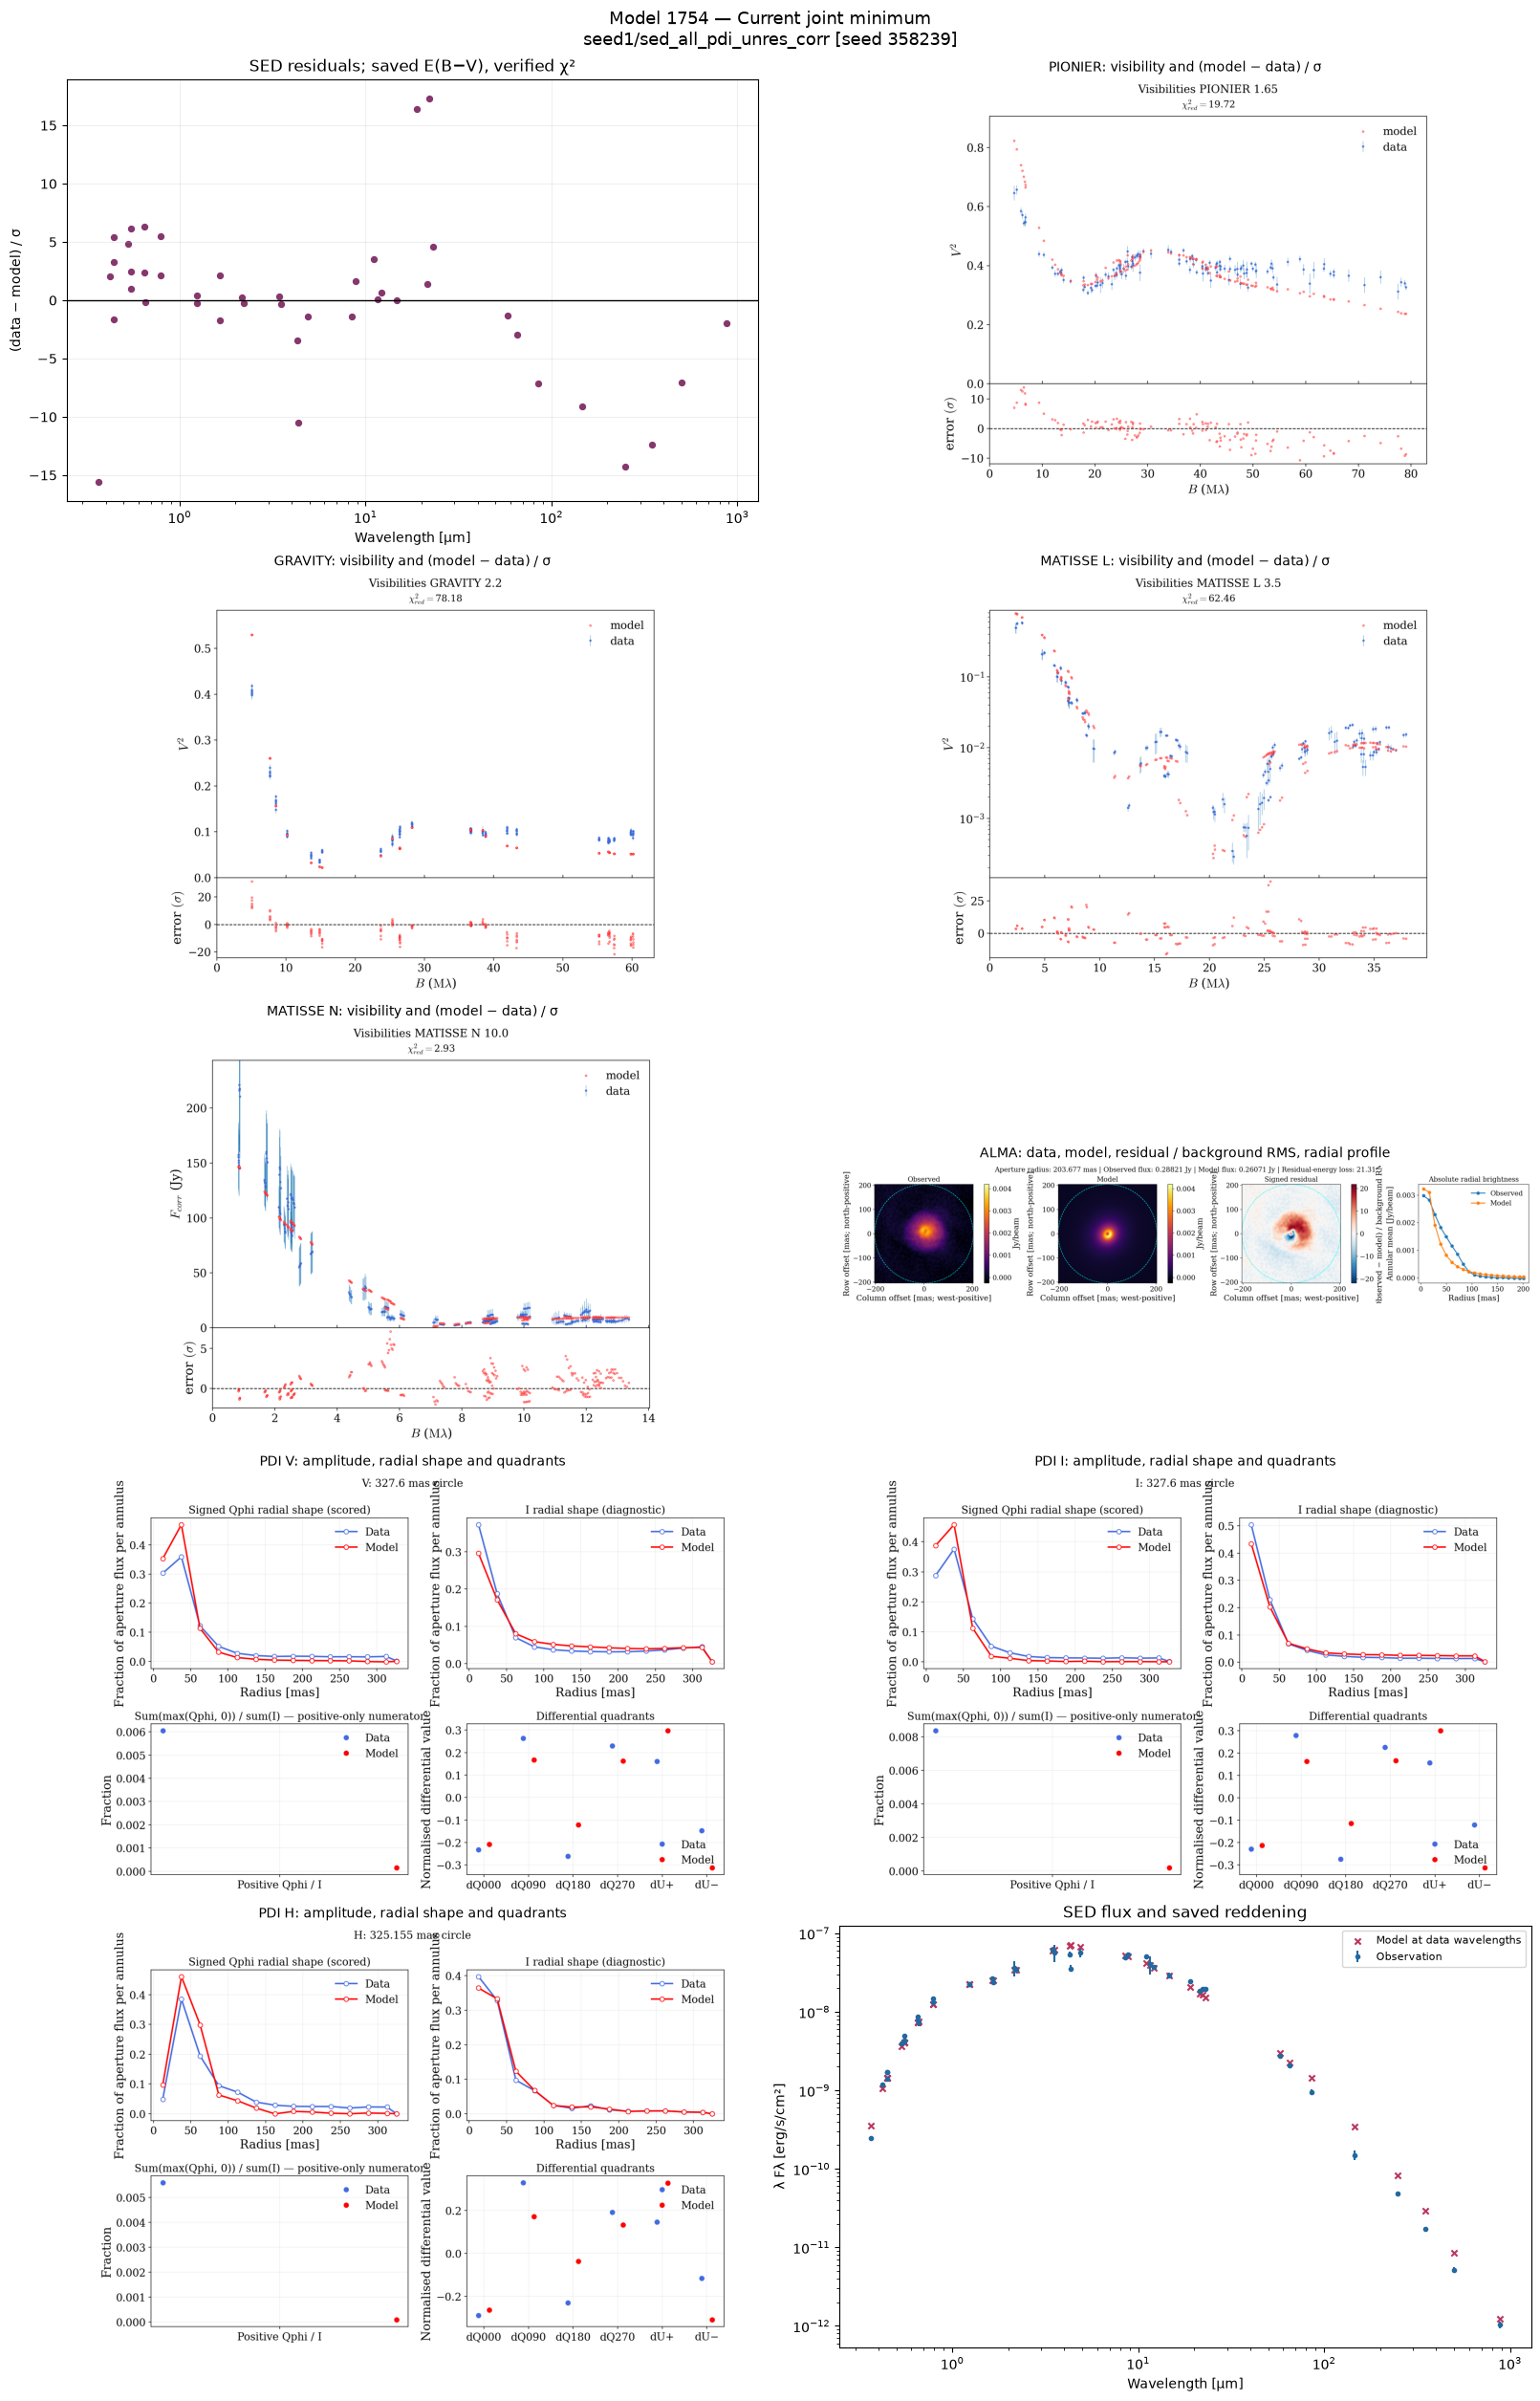

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

...

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/visibilities_GRAVITY 2.2.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/visibilities_MATISSE L 3.5.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/visibilities_MATISSE N 10.0.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/visibilities_PIONIER 1.65.png

**Model 1778: Sampled alternative family 2**

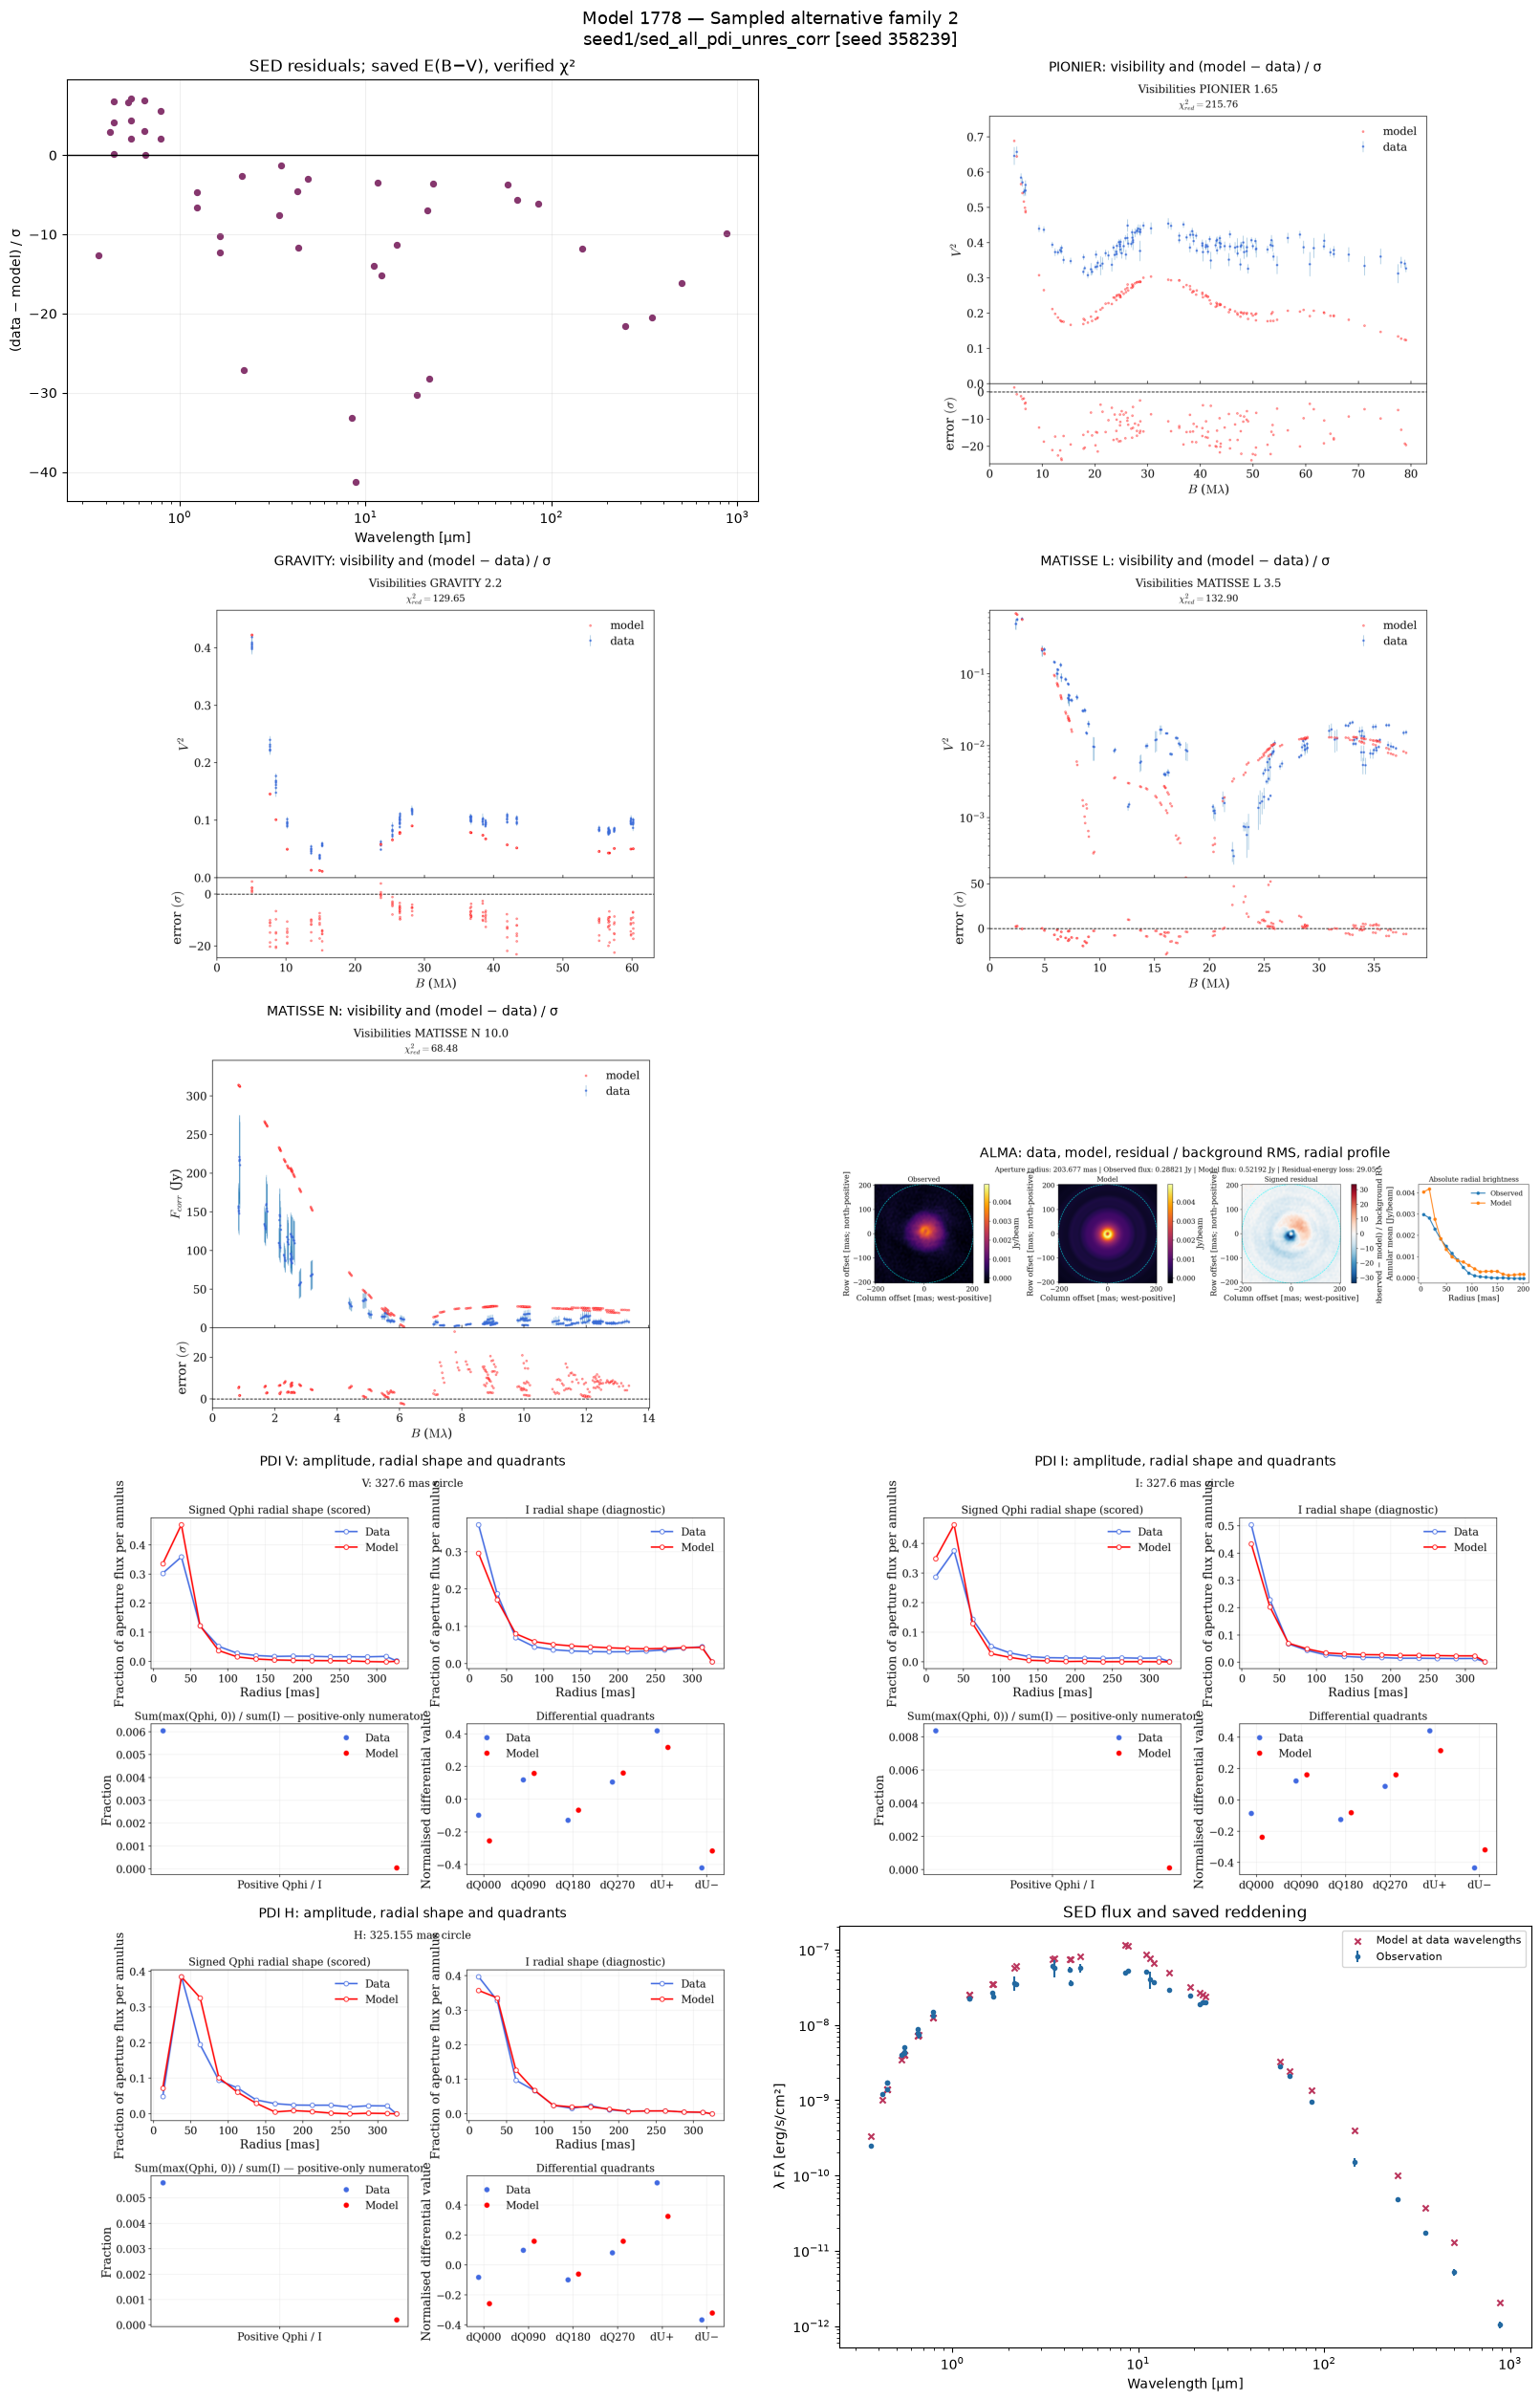

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

...

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/visibilities_GRAVITY 2.2.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/visibilities_MATISSE L 3.5.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/visibilities_MATISSE N 10.0.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/visibilities_PIONIER 1.65.png

**Model 1825: Sampled alternative family 3**

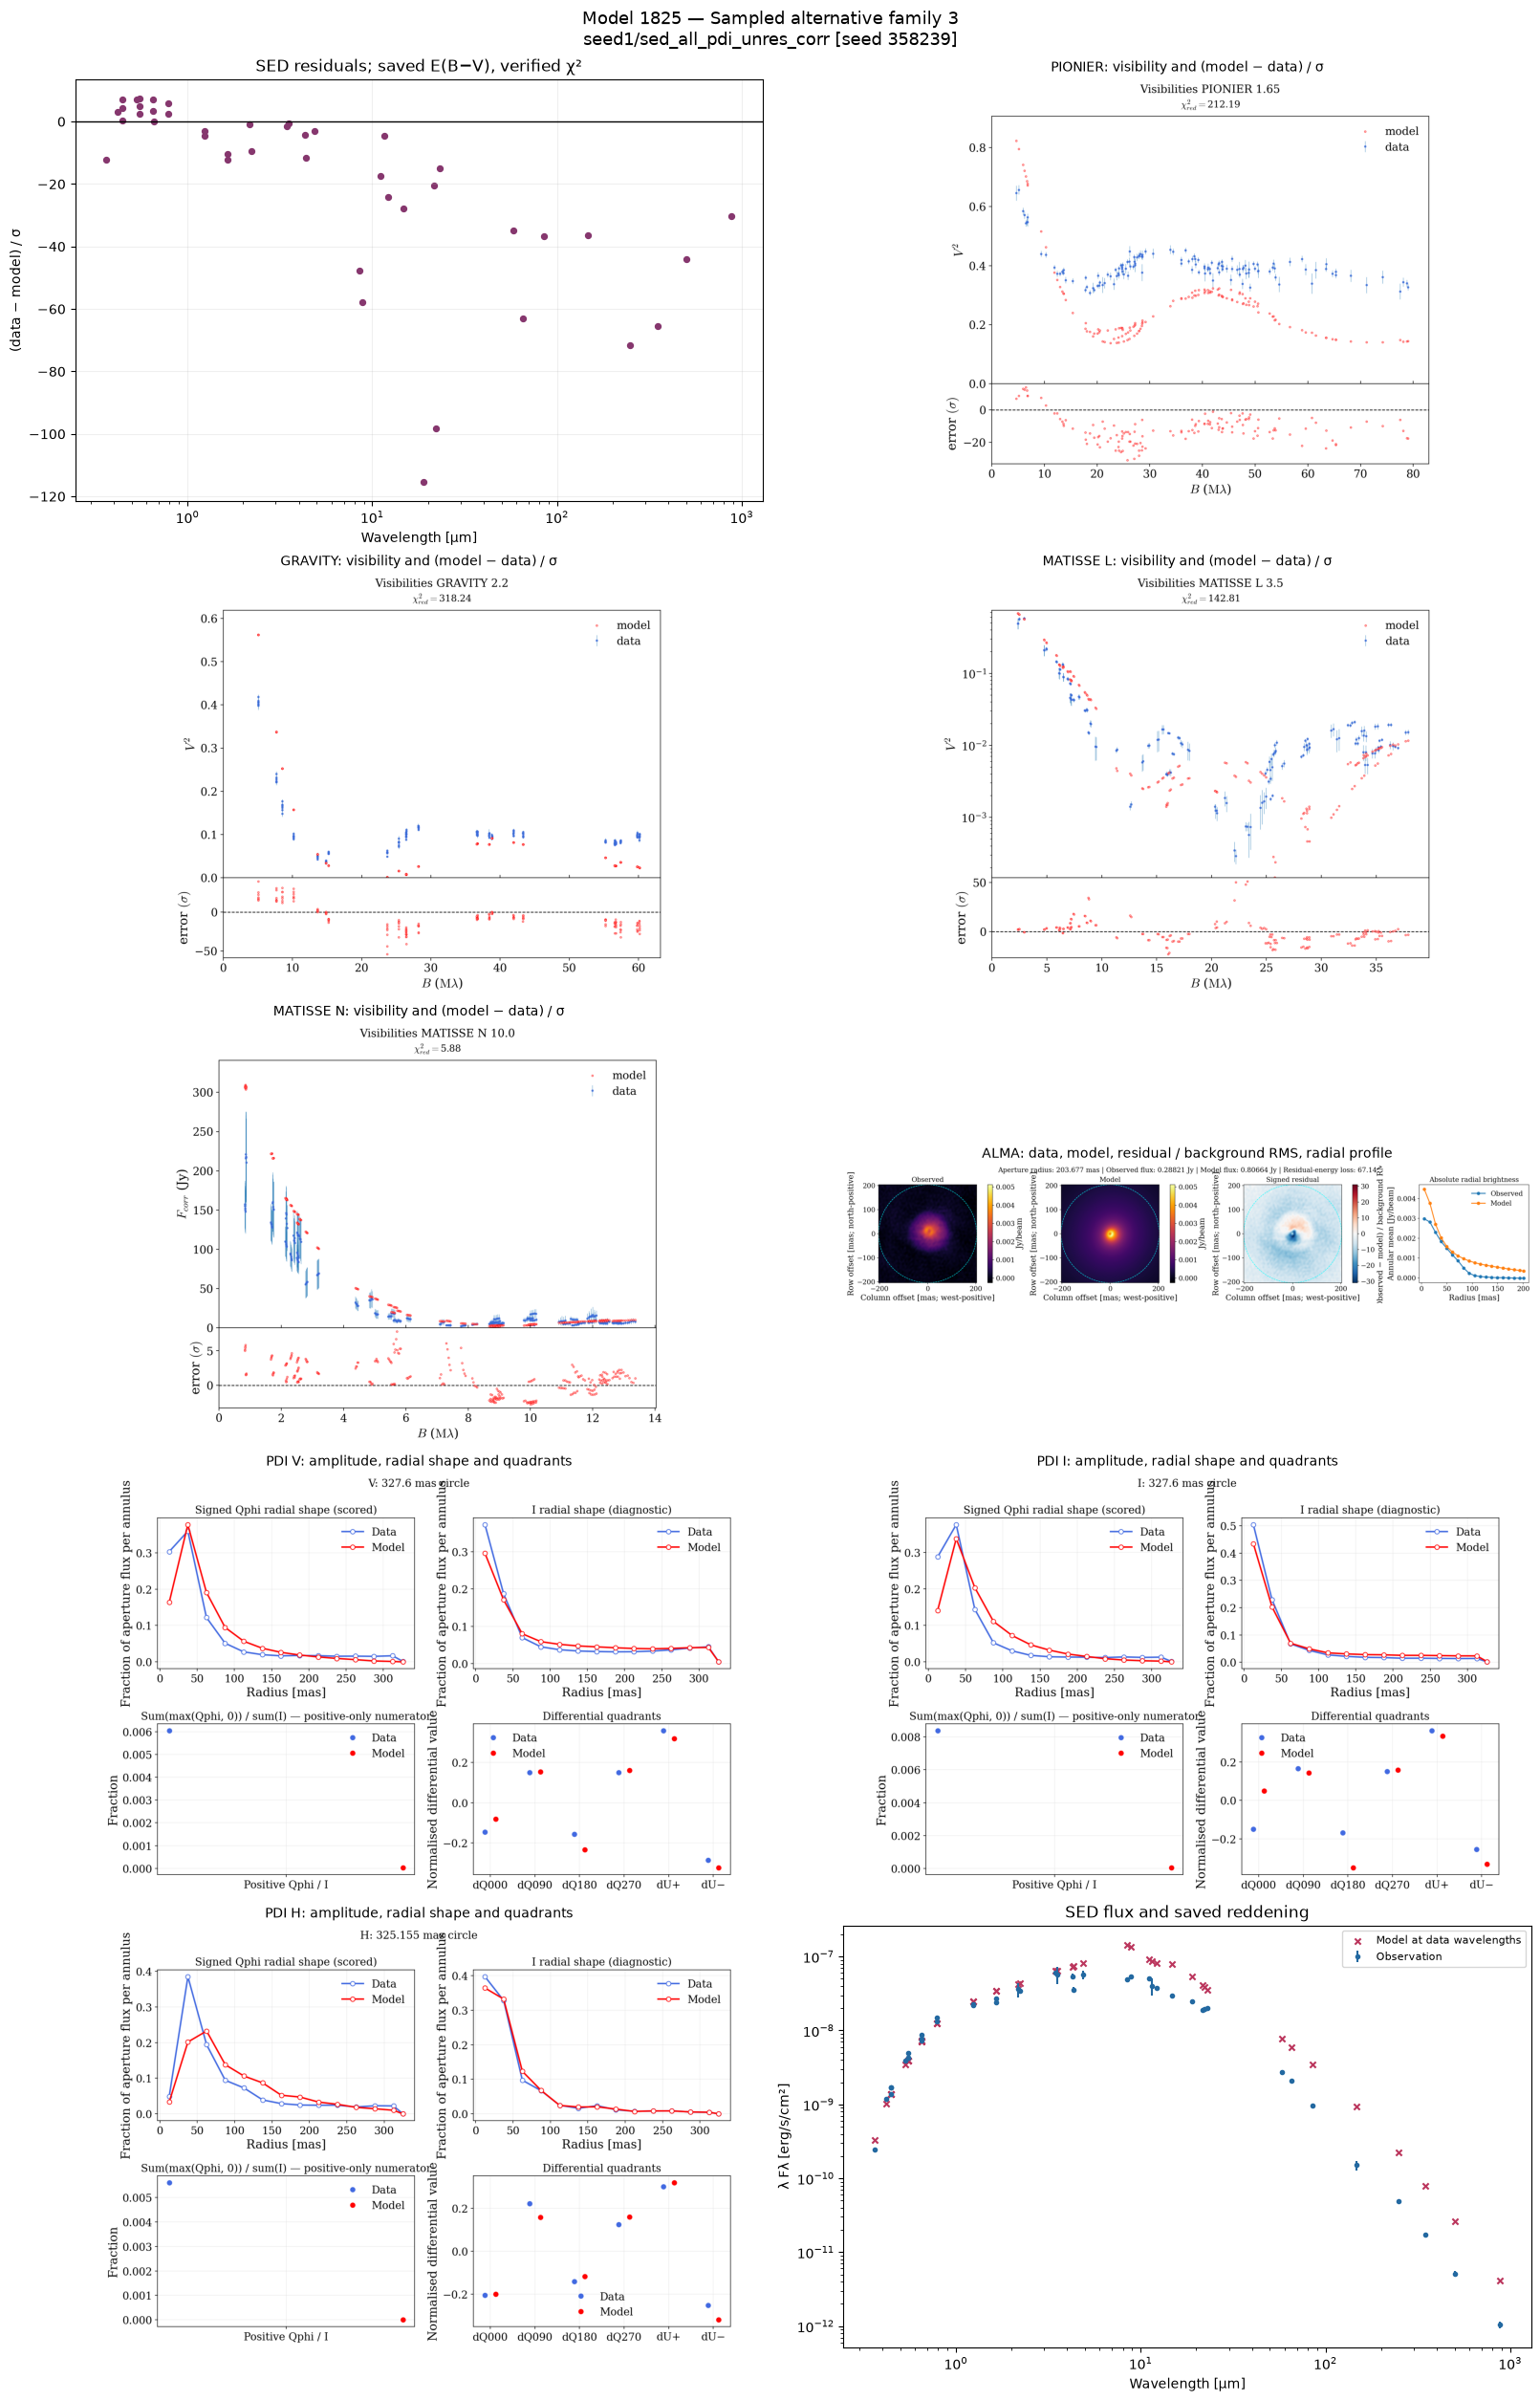

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

...

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/visibilities_GRAVITY 2.2.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/visibilities_MATISSE L 3.5.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/visibilities_MATISSE N 10.0.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_62_budget_1.00/figures/visibilities_PIONIER 1.65.png

**Model 1581: SED minimum / pool 4016ff65**

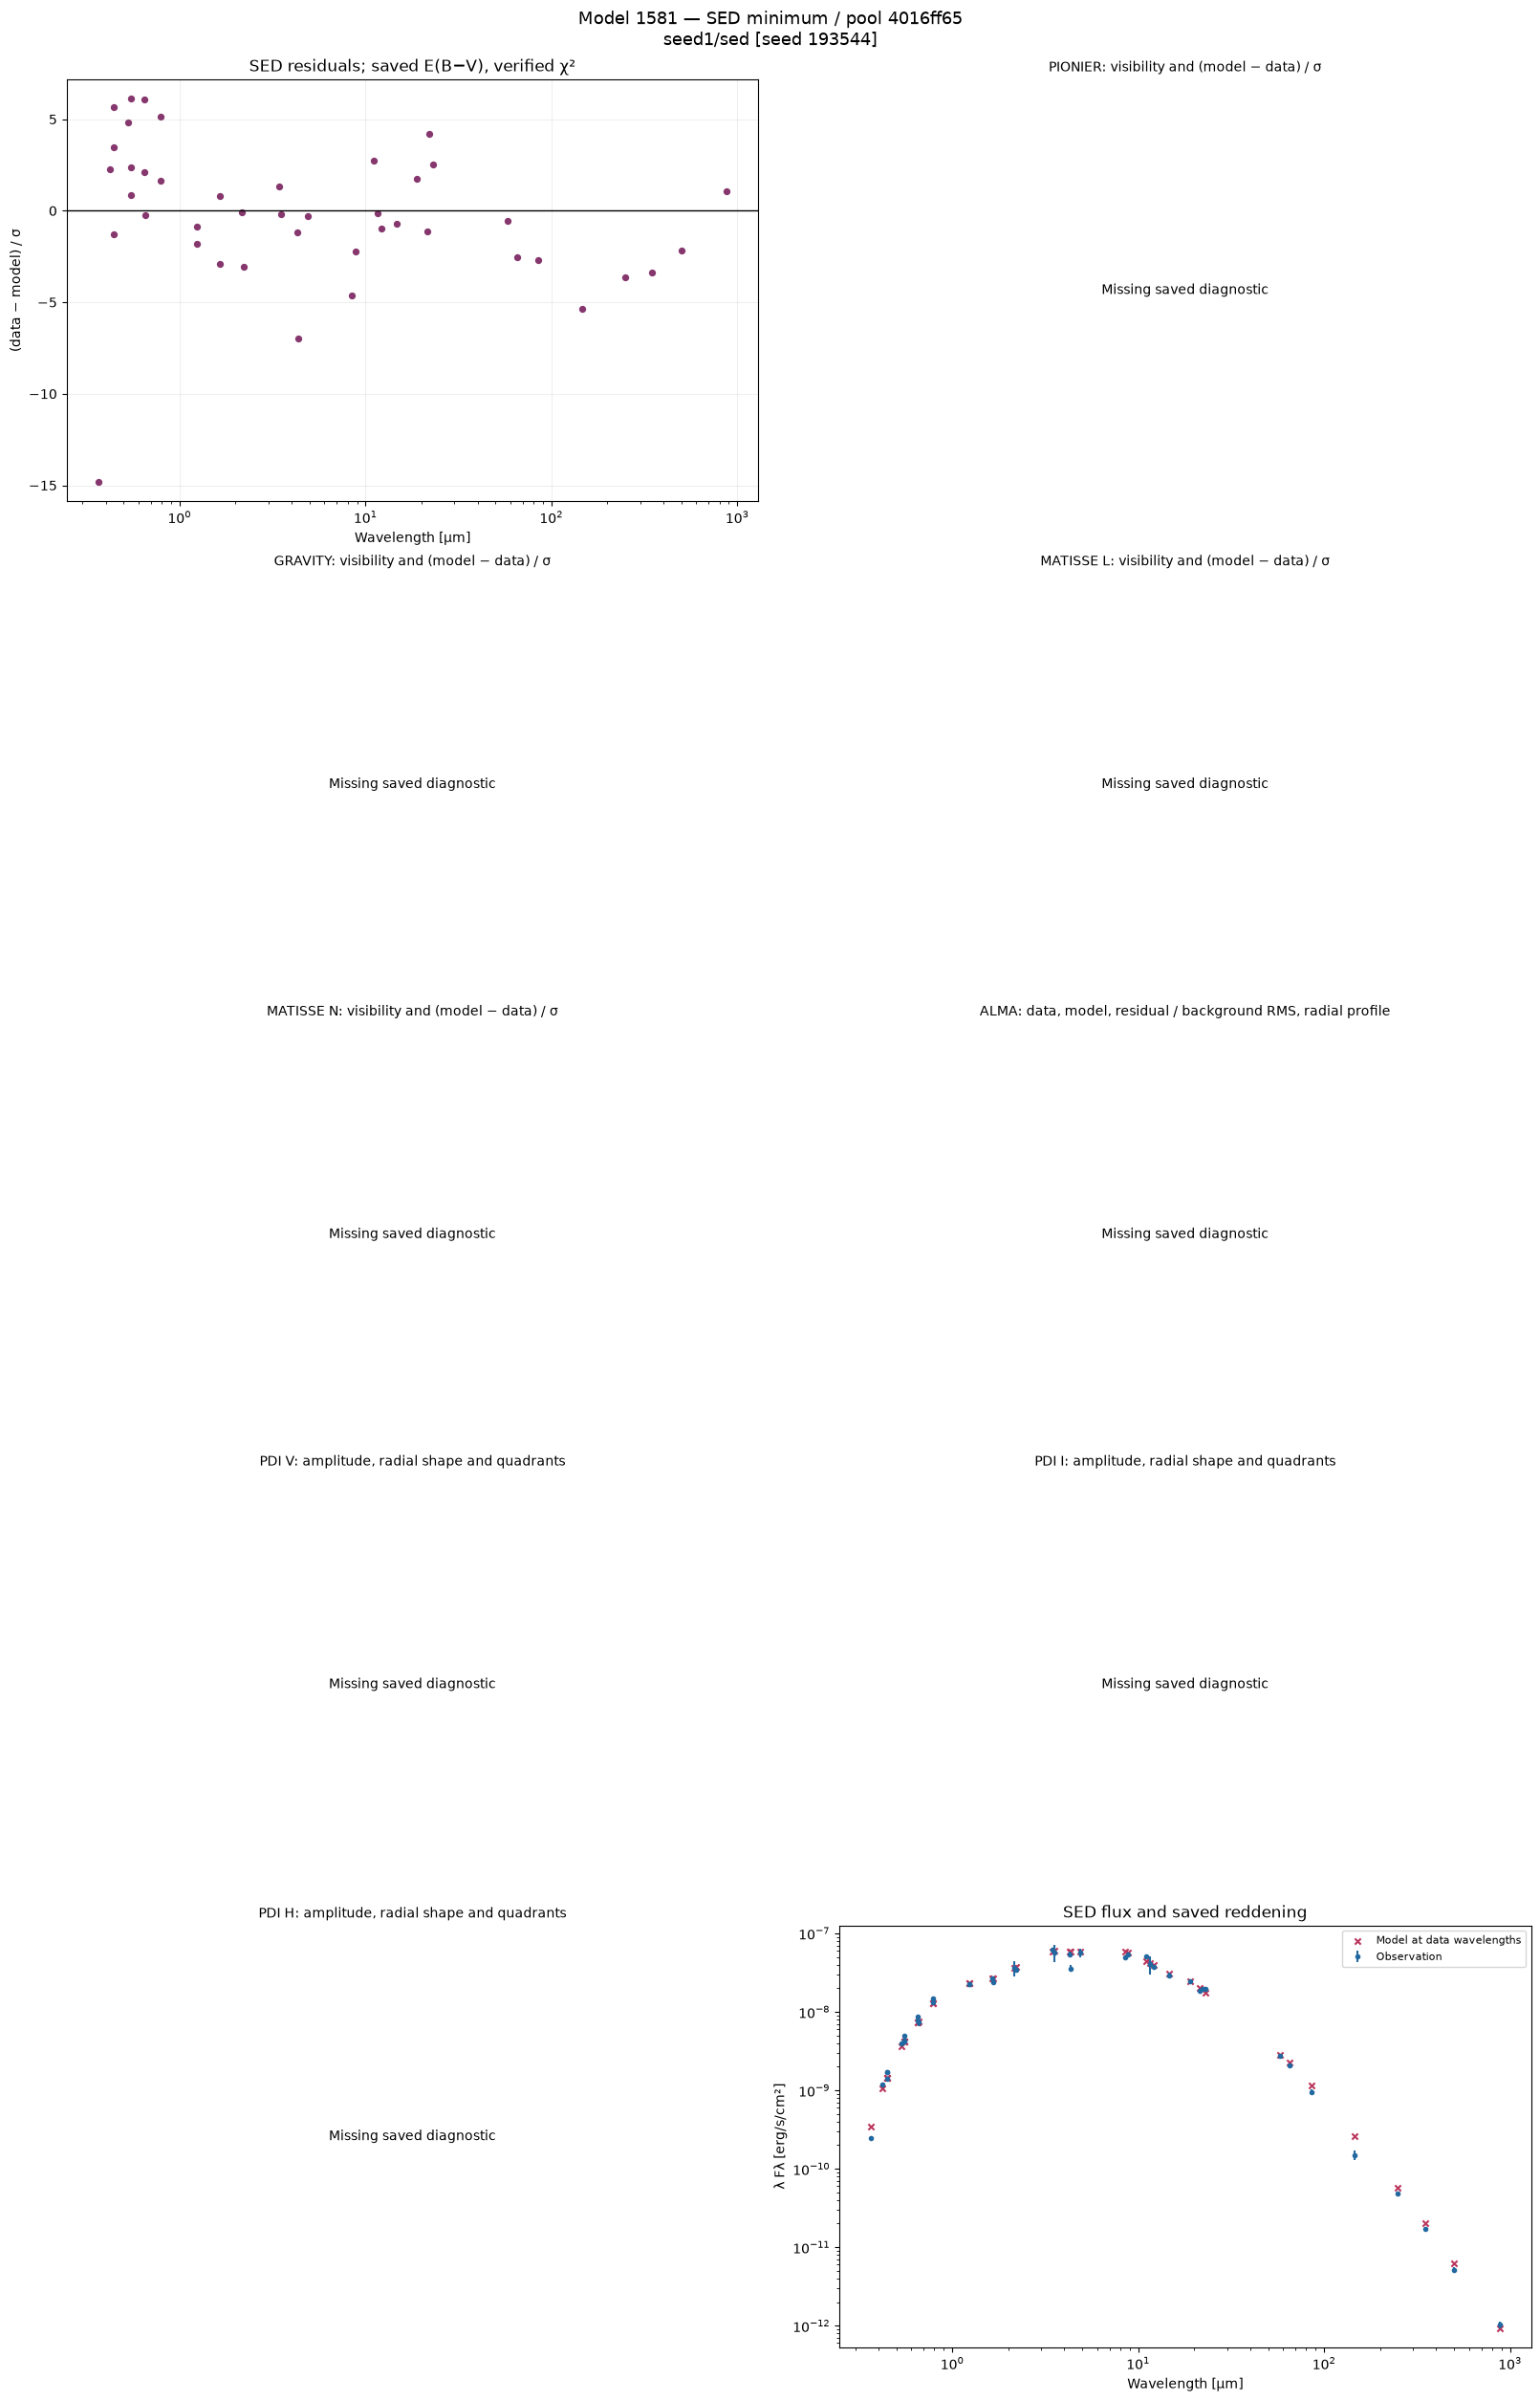

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed/trials/config_1000_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed/trials/config_1000_budget_1.00/SED_secondary_comparison.png

**Model 3052: INT minimum / pool 8d640dae**

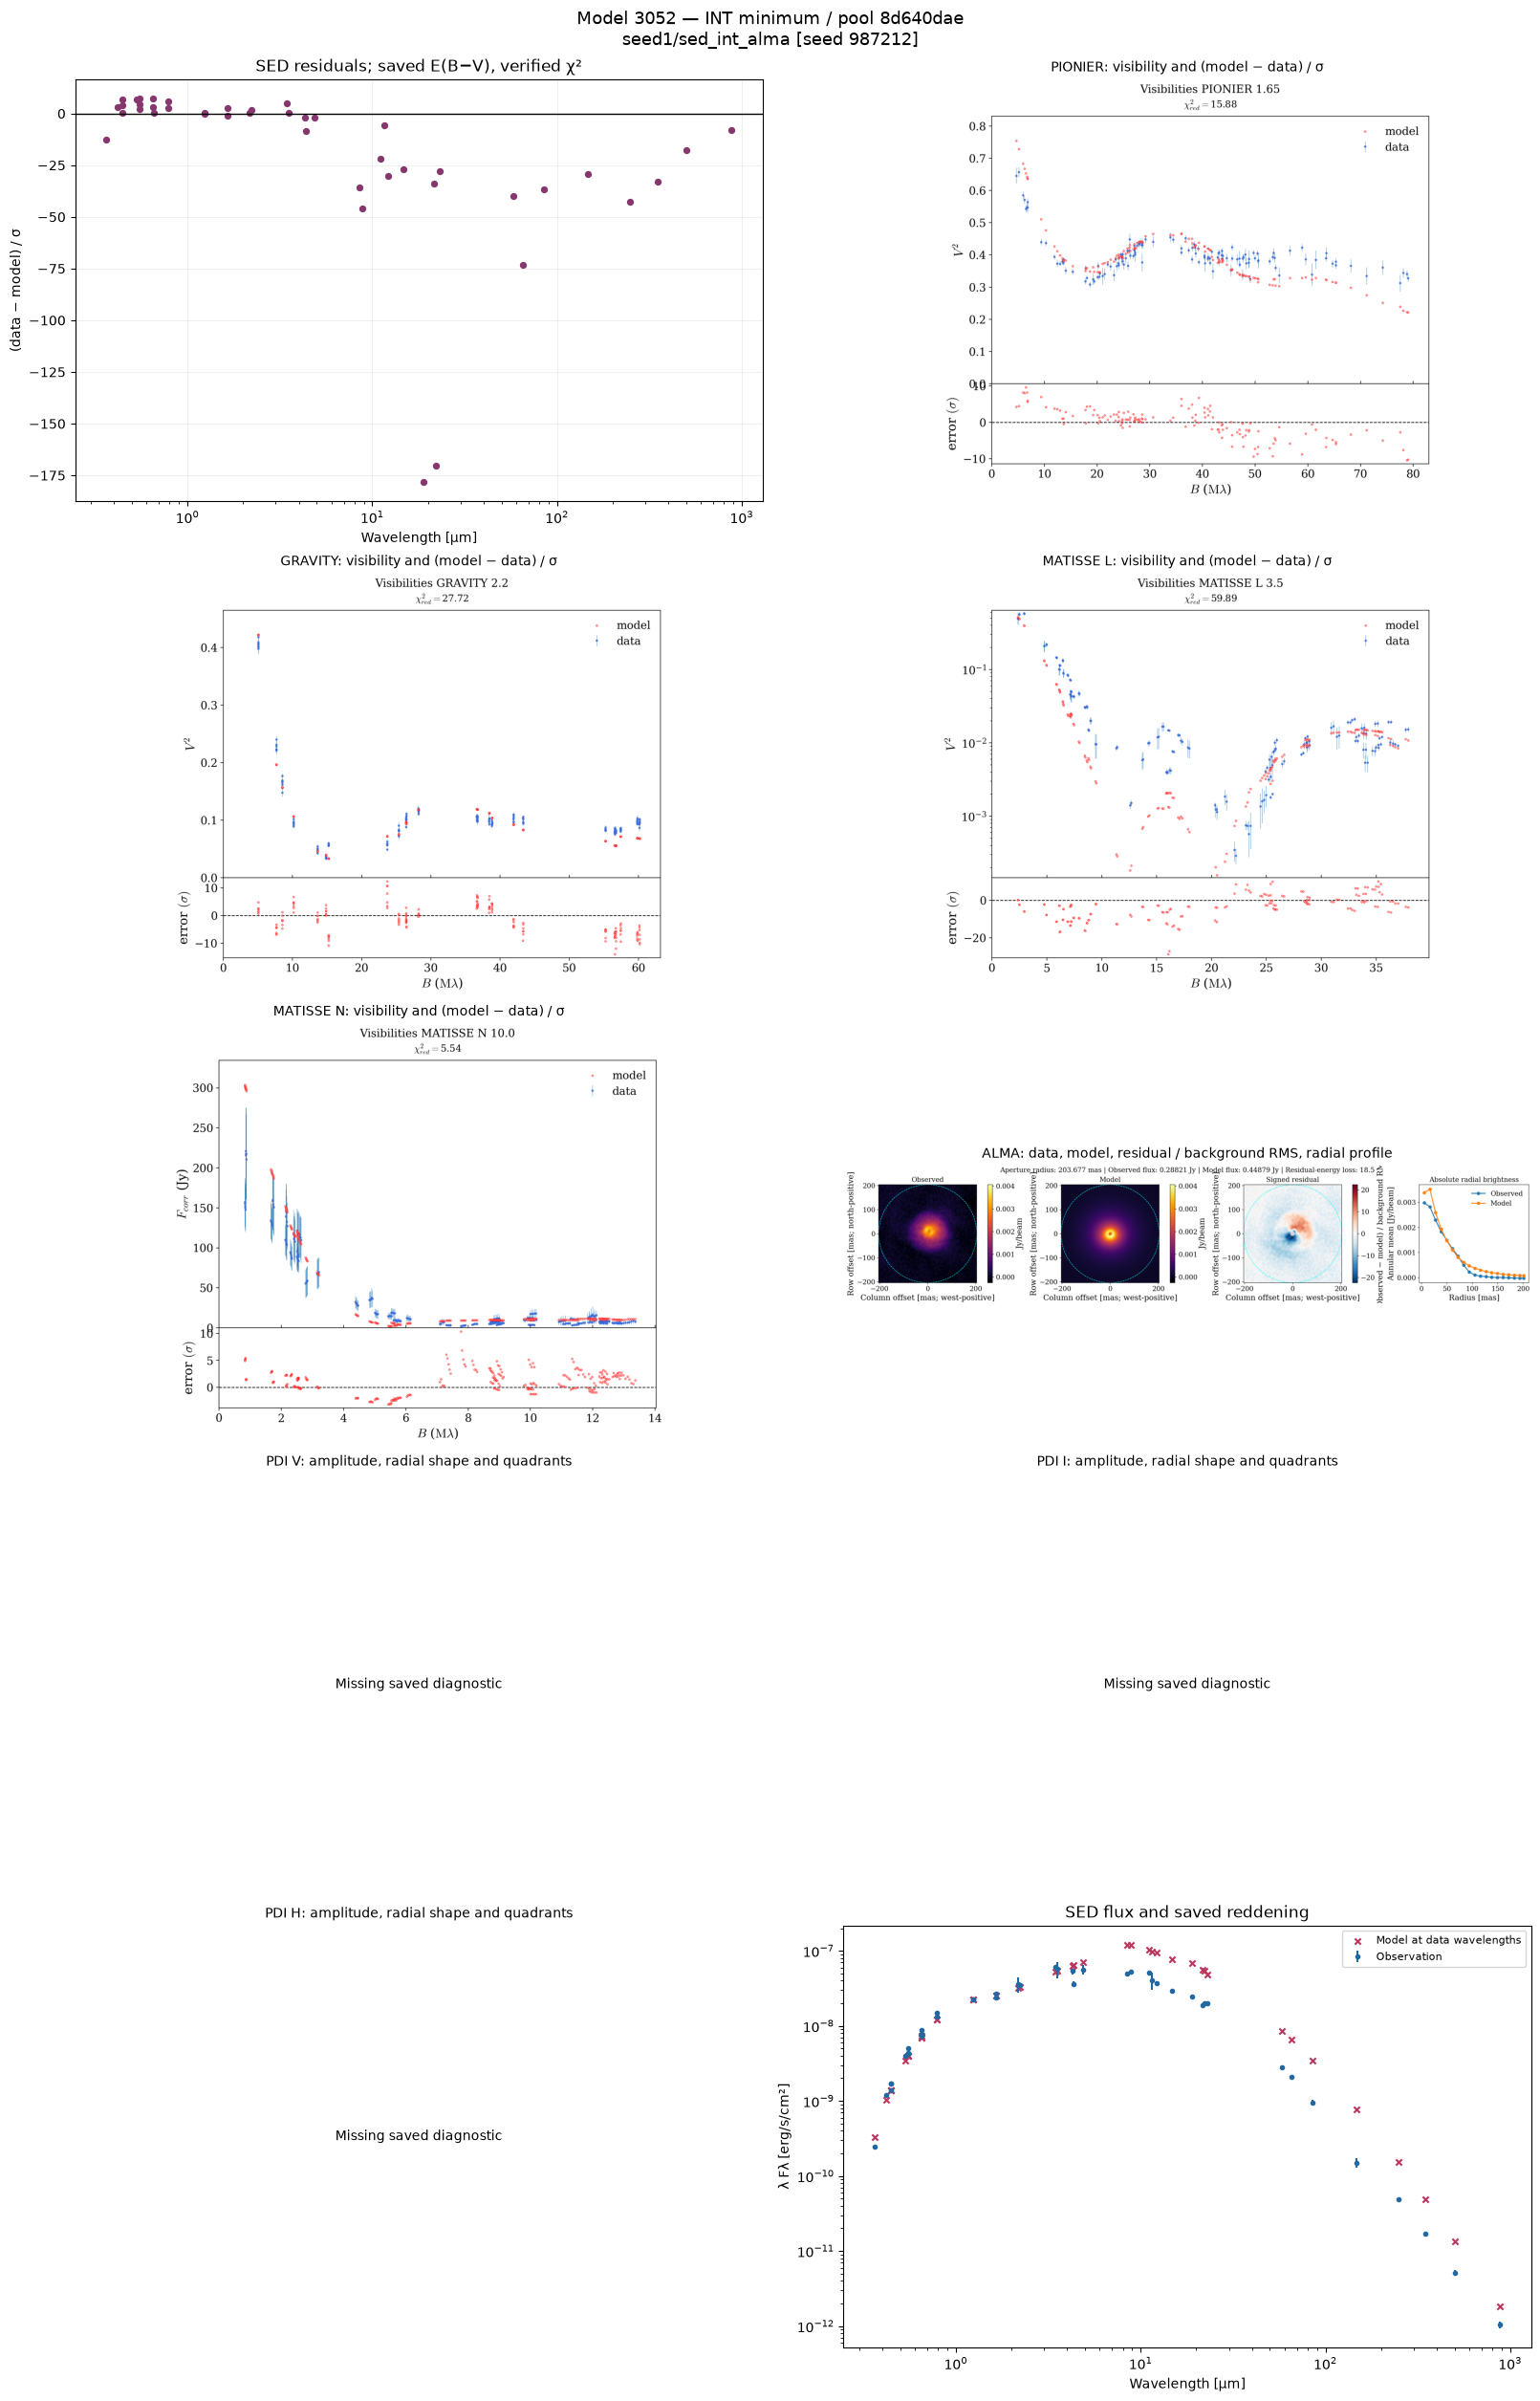

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/figures/visibilities_GRAVITY 2.2.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/figures/visibilities_MATISSE L 3.5.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/figures/visibilities_MATISSE N 10.0.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/trials/config_266_budget_1.00/figures/visibilities_PIONIER 1.65.png

**Model 0320: PDI minimum / pool 322a7602**

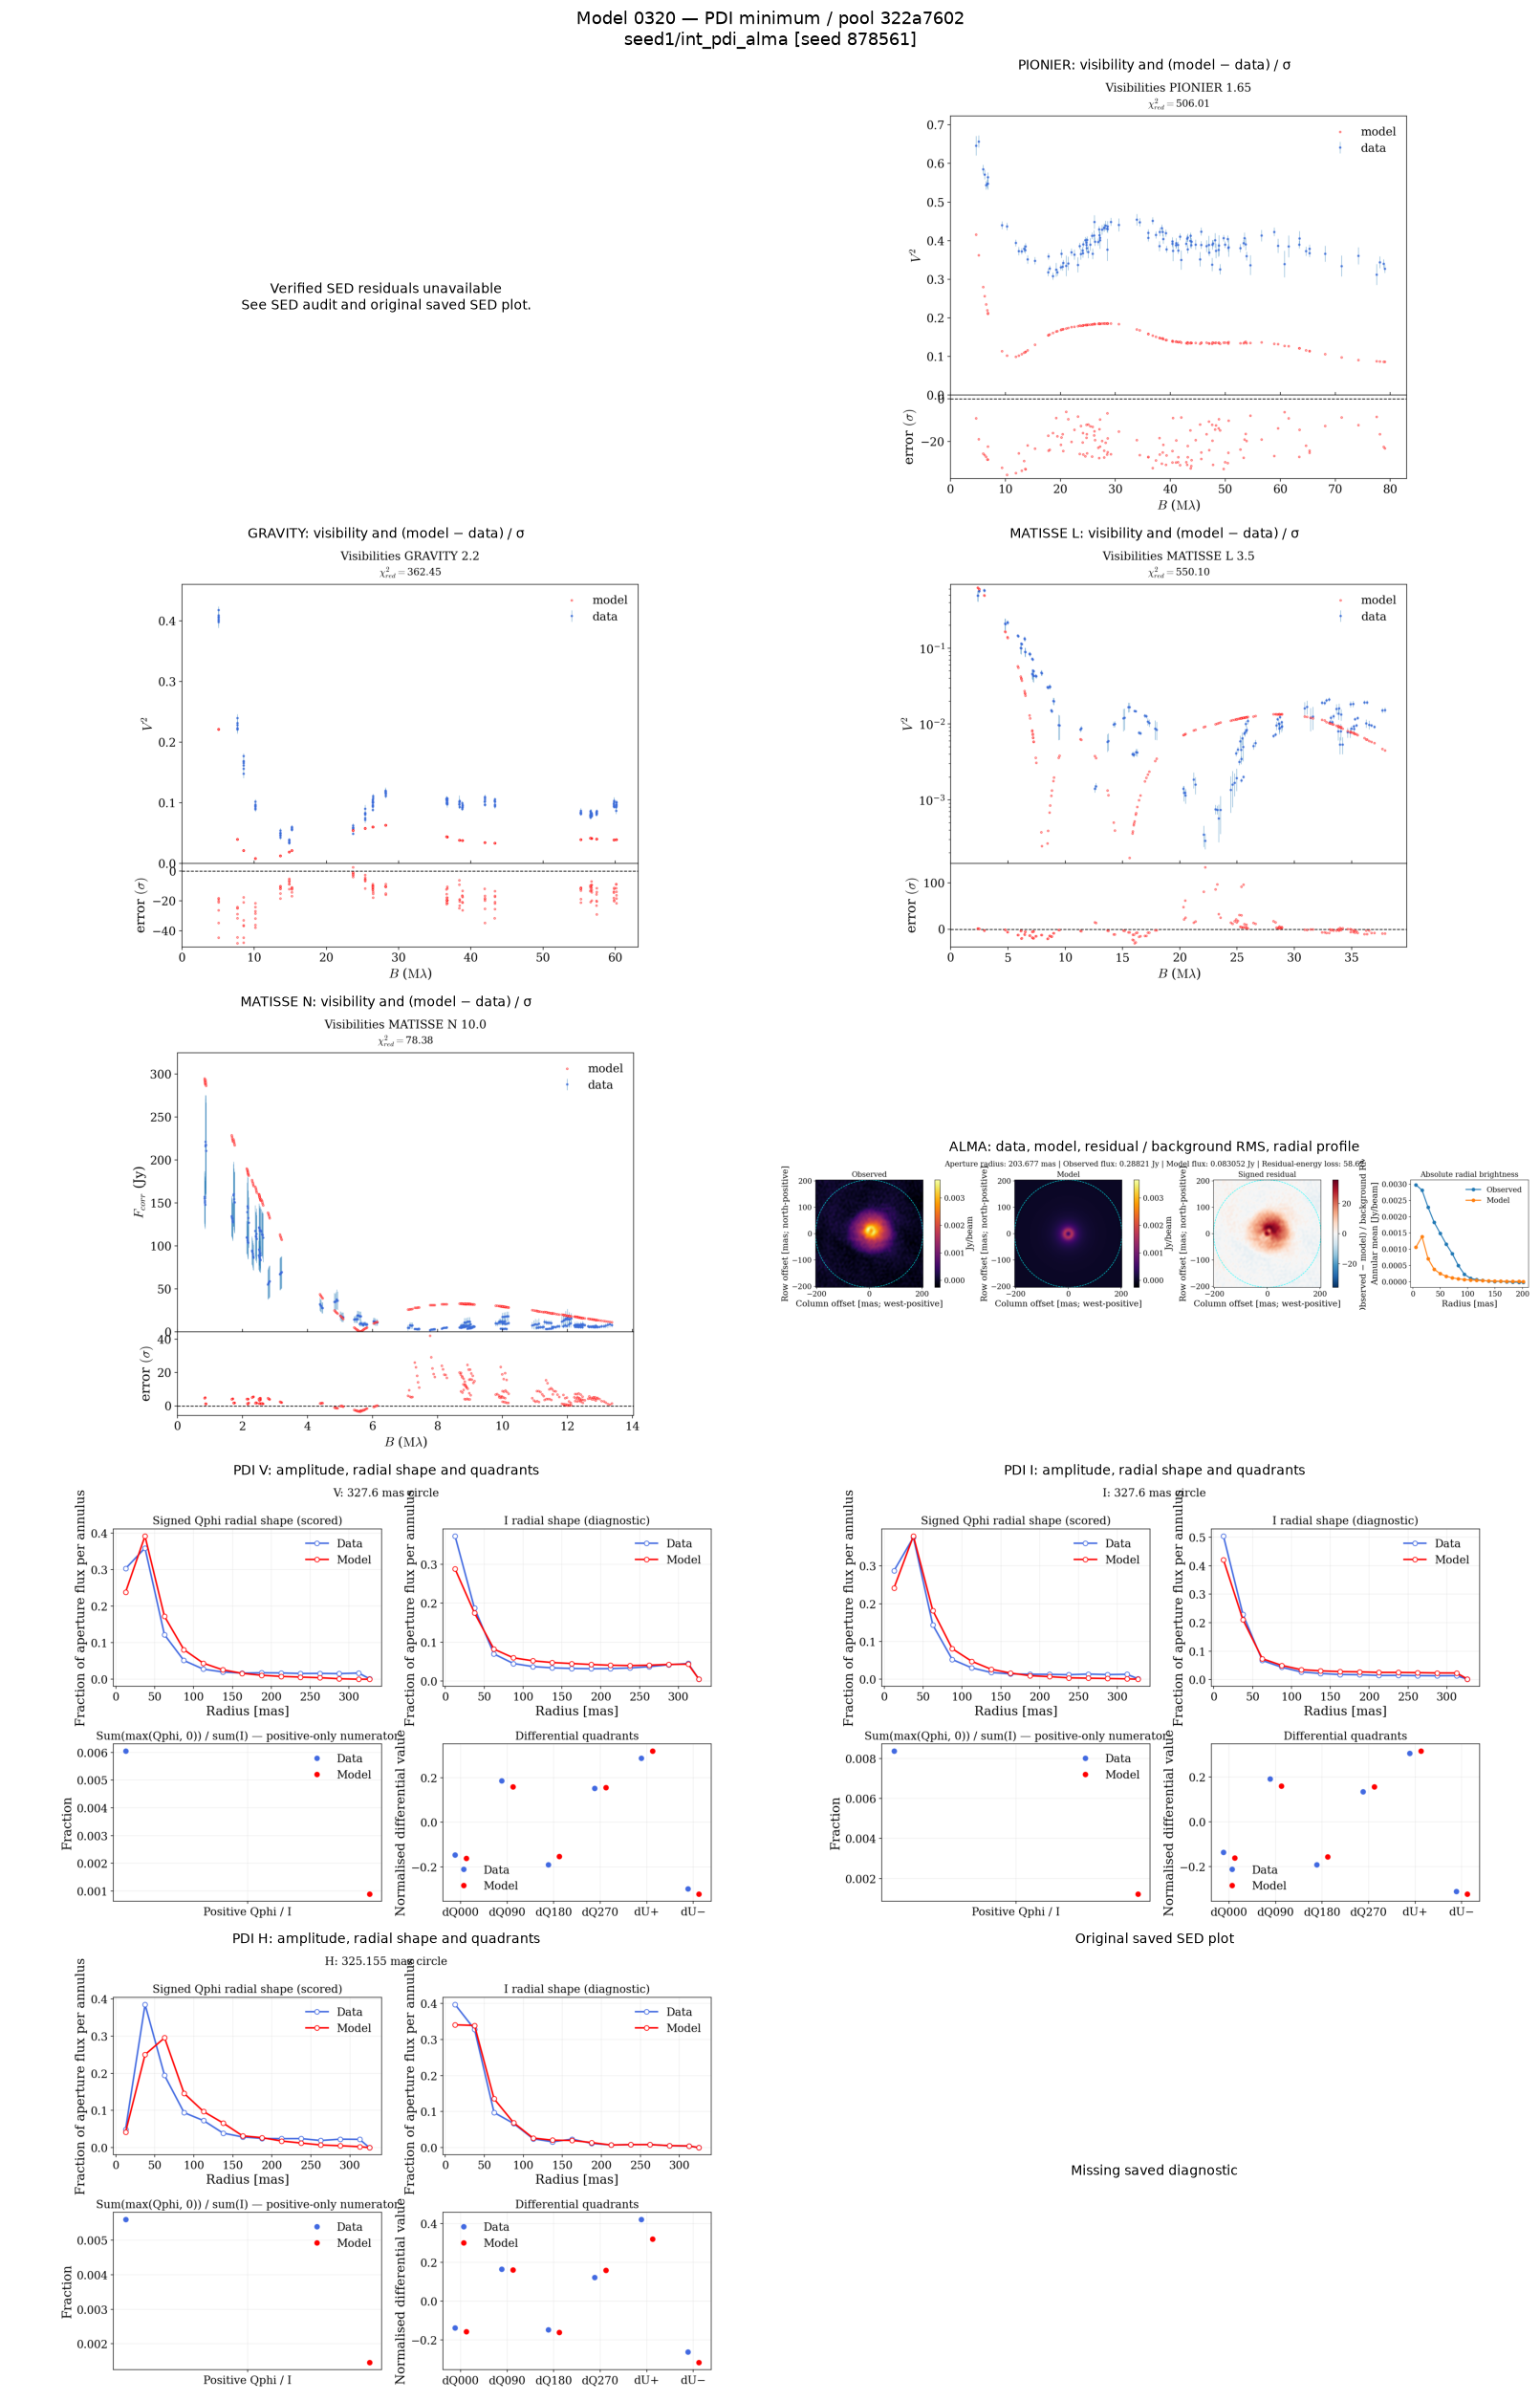

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/pdi_constraints_i.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/pdi_constraints_i_model_quadrants_slides.png

...

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/visibilities_GRAVITY 2.2.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/visibilities_MATISSE L 3.5.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/visibilities_MATISSE N 10.0.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/trials/config_387_budget_1.00/figures/visibilities_PIONIER 1.65.png

**Model 4970: PDI minimum / pool 58c68d21**

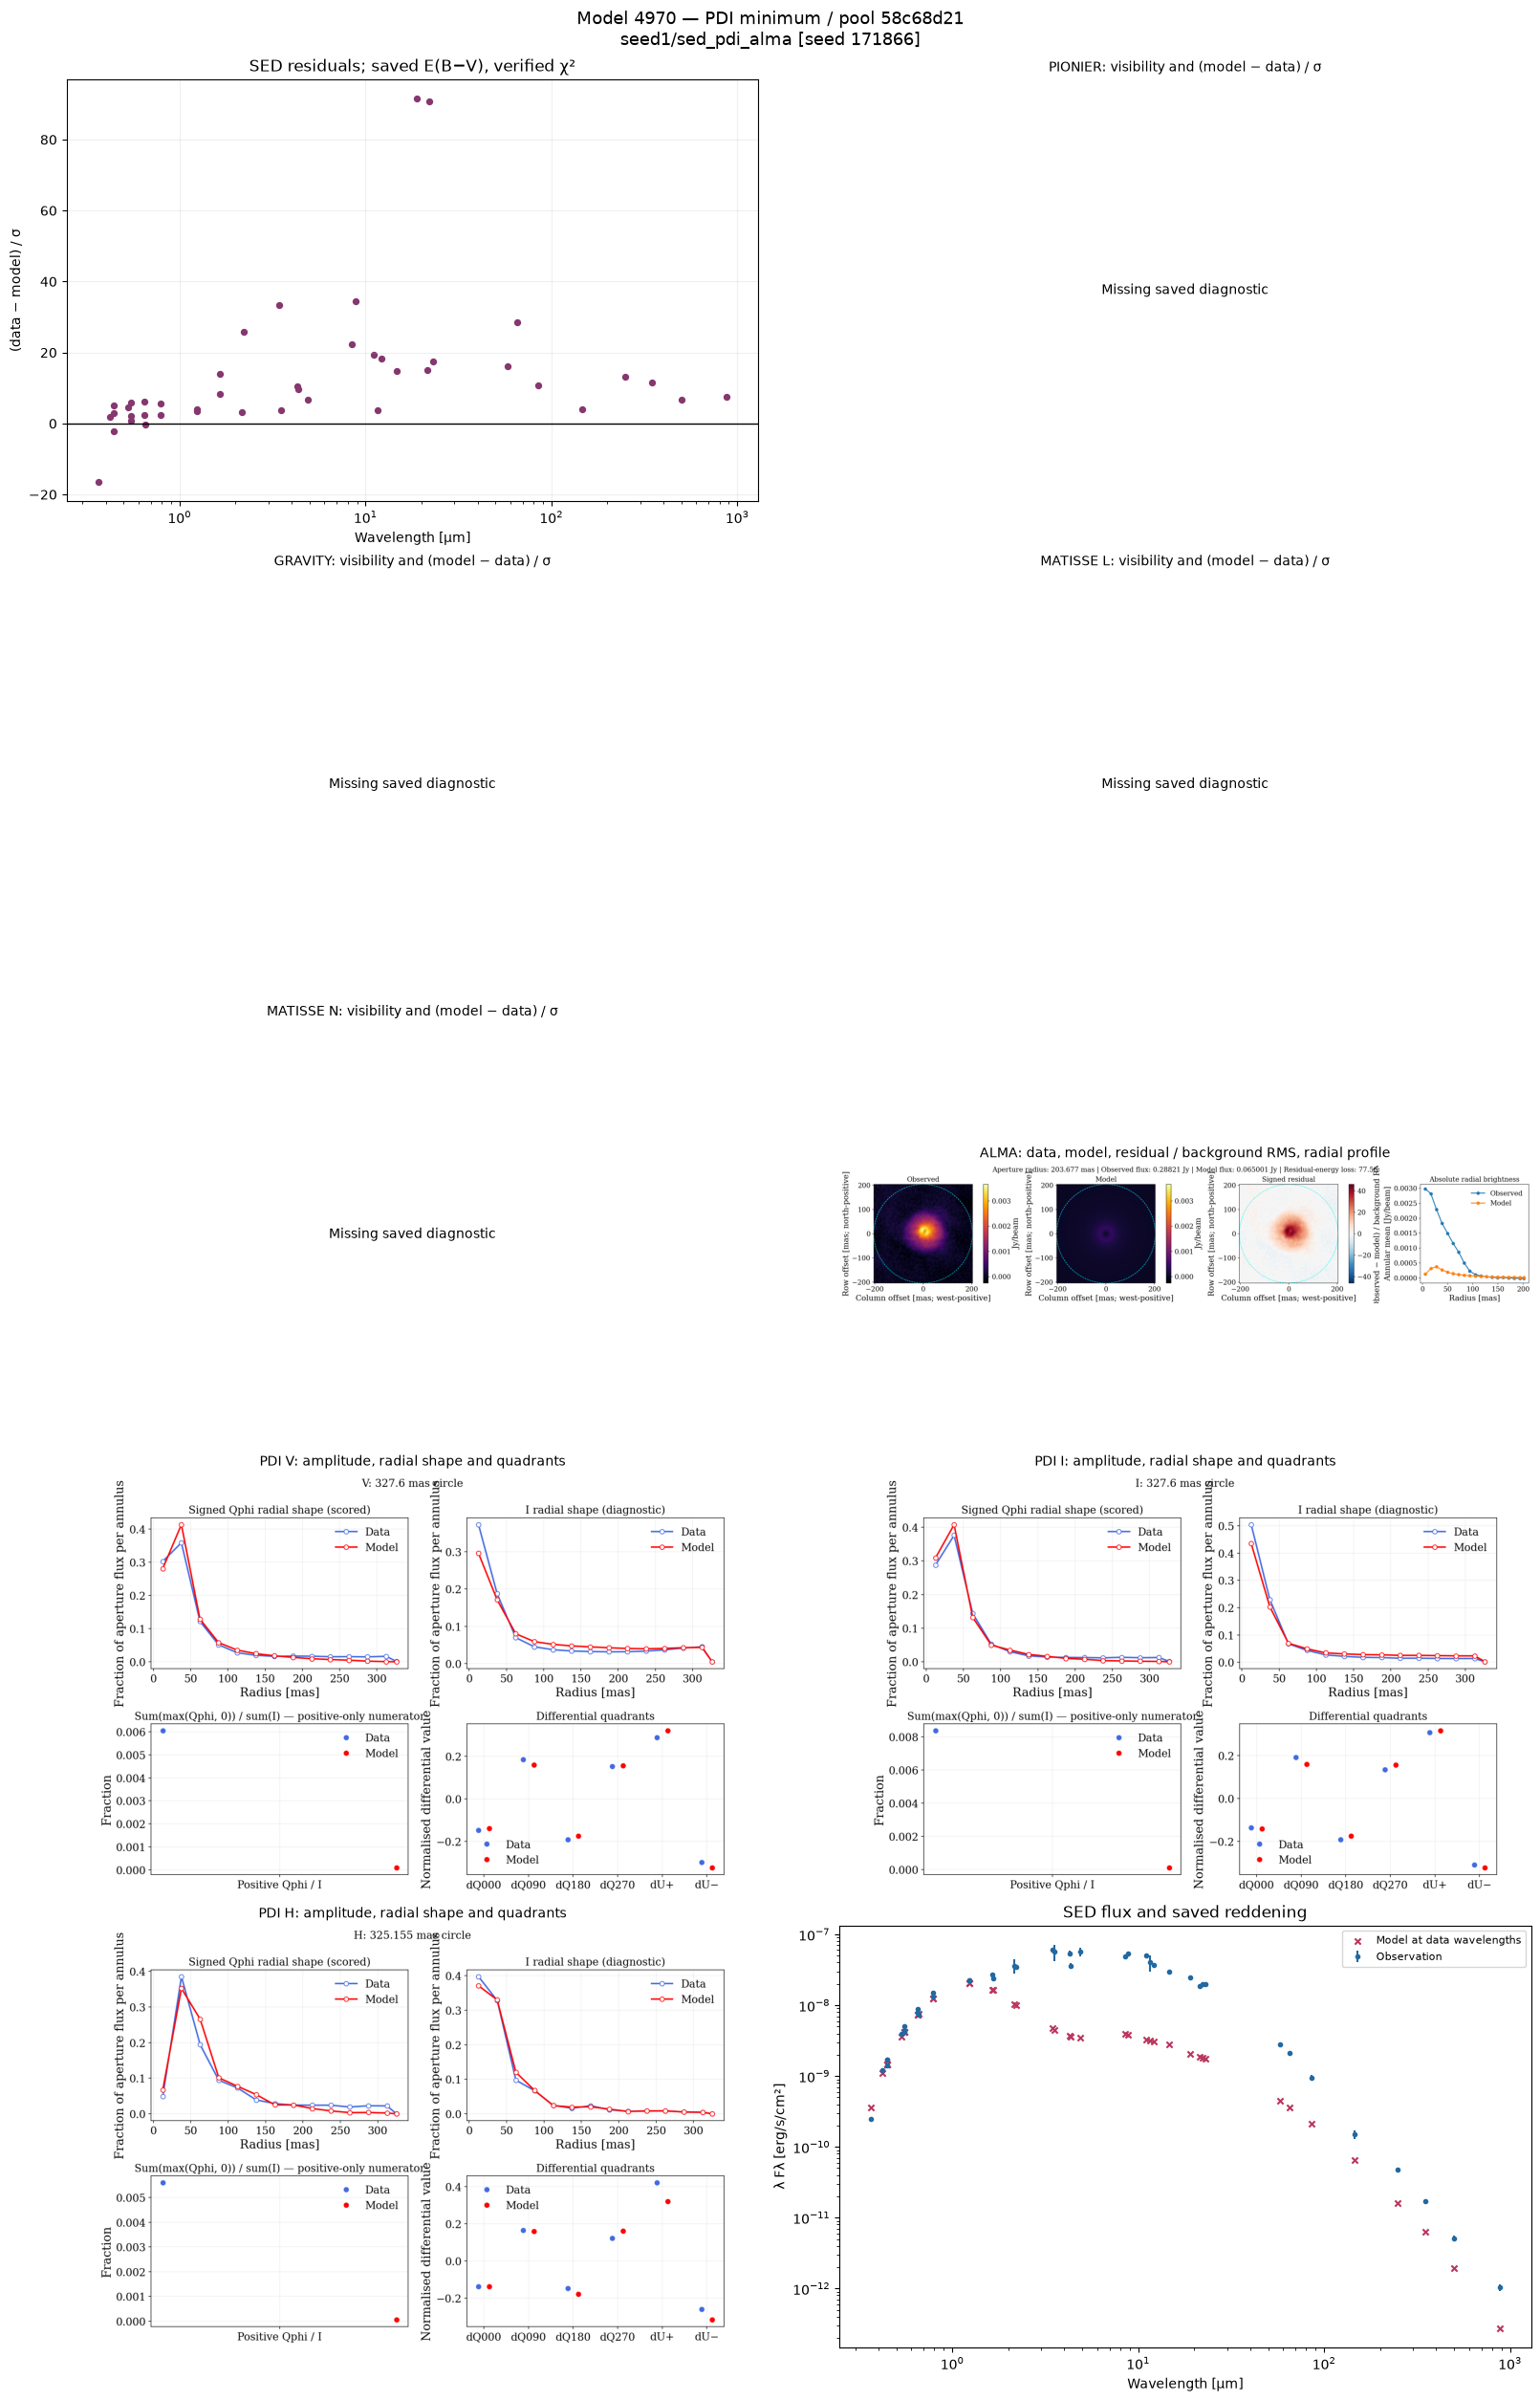

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/pdi_constraints_i.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/pdi_constraints_i_model_quadrants_slides.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/pdi_constraints_v.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/trials/config_283_budget_1.00/figures/pdi_constraints_v_model_quadrants_slides.png

**Model 1822: ALMA minimum / pool 832f4cf8**

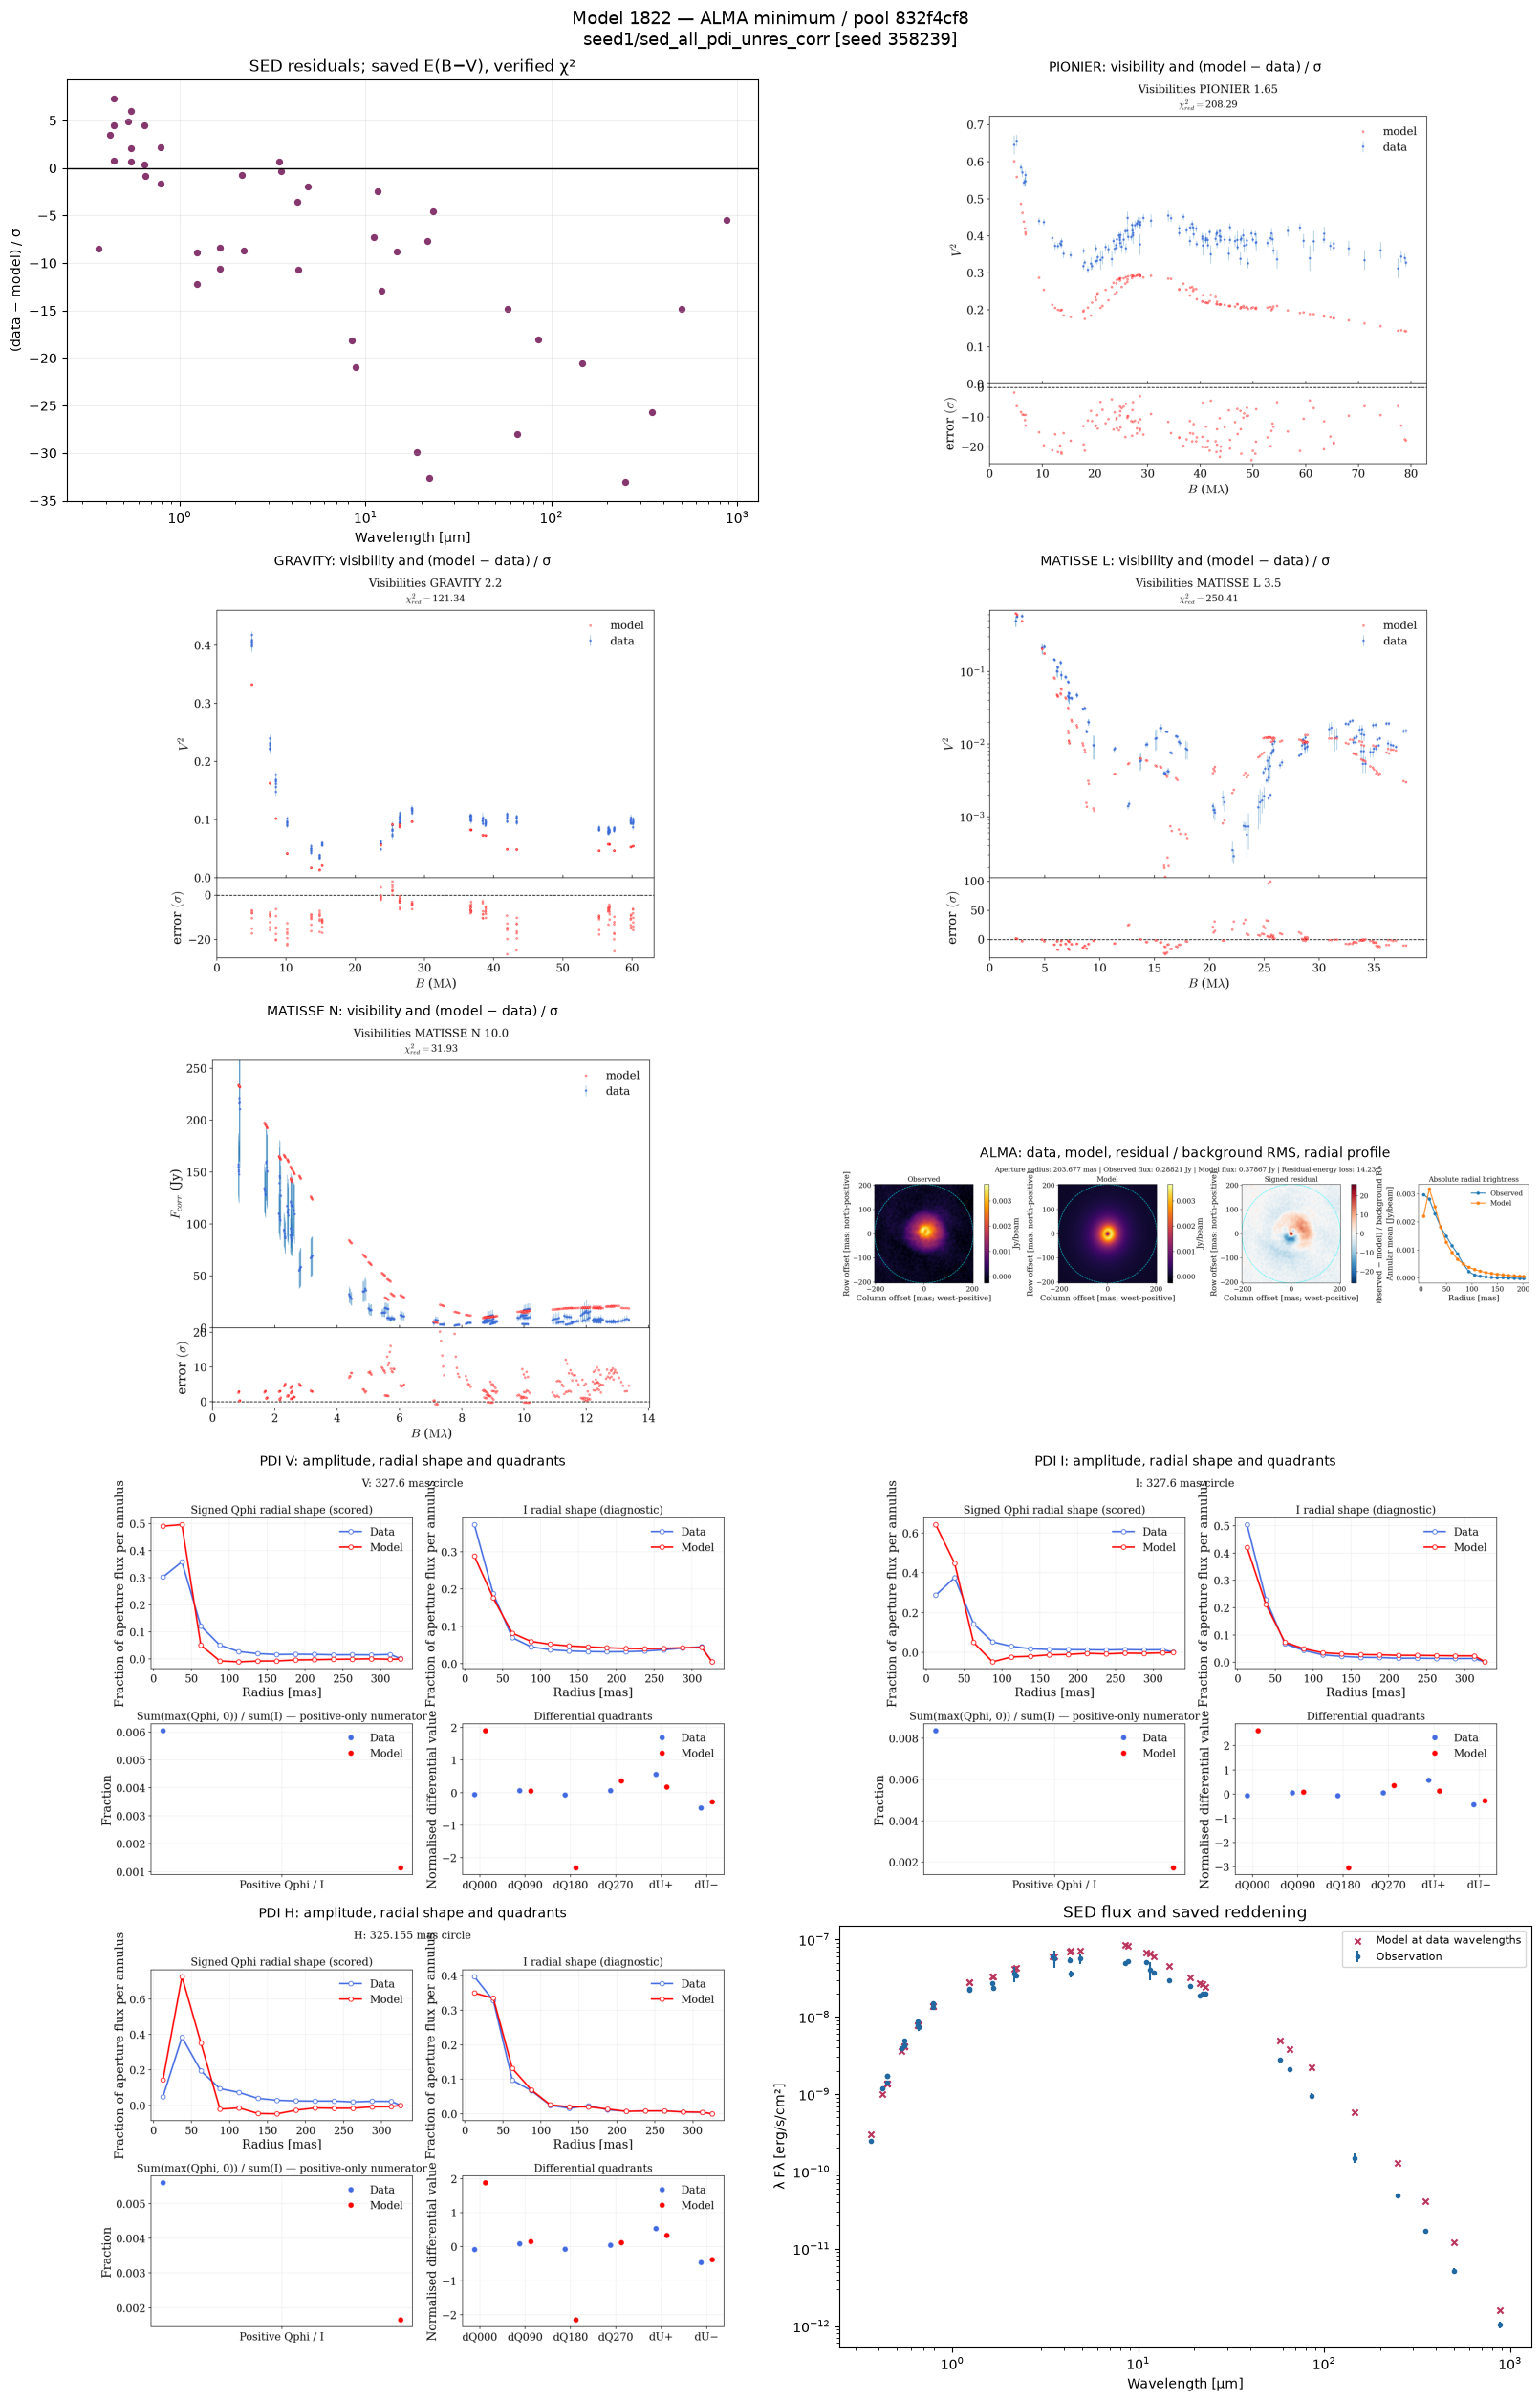

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

...

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/figures/visibilities_MATISSE L 3.5.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/figures/visibilities_MATISSE N 10.0.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_60_budget_1.00/figures/visibilities_PIONIER 1.65.png

,evaluation_id,history,band,observed_fraction,model_fraction,model_over_observed,corrected,correction_radius_px,fraction_loss,radial_loss,quadrant_loss,band_loss,ssim_diagnostic,model_id
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,1.848885e-04,0.022099,True,3.0,6.693604,14.437227,503.228256,524.359088,0.832597,Model 1754
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,1.436125e-04,0.023749,True,3.0,3.484962,12.206710,402.304600,417.996272,0.814381,Model 1754
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,8.825030e-05,0.015765,True,3.0,3.035761,17.422114,682.030130,702.488005,0.714139,Model 1754
3,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,9.471737e-05,0.011321,True,3.0,6.841963,9.861602,307.469119,324.172684,0.865111,Model 1778
4,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,3.989704e-05,0.006598,True,3.0,3.608492,11.037914,271.638856,286.285262,0.860496,Model 1778
5,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,1.996388e-04,0.035662,True,3.0,2.914256,15.015393,473.086834,491.016483,0.733463,Model 1778
6,seed1/sed_all_pdi_unres_corr [seed 358239]/row_61,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,4.367063e-05,0.005220,True,3.0,6.926671,23.679303,401.919448,432.525423,0.728527,Model 1825
7,seed1/sed_all_pdi_unres_corr [seed 358239]/row_61,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,1.969267e-05,0.003257,True,3.0,3.632806,20.120898,65.668494,89.422199,0.758691,Model 1825
8,seed1/sed_all_pdi_unres_corr [seed 358239]/row_61,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,4.178674e-07,0.000075,True,3.0,3.133320,30.005233,53.657123,86.795675,-0.369538,Model 1825
9,seed1/int_pdi_alma [seed 878561]/row_386,seed1/int_pdi_alma [seed 878561],I,0.008366,1.214148e-03,0.145123,True,3.0,5.115375,3.760905,18.620949,27.497229,0.865927,Model 0320


,evaluation_id,history,observed_flux_jy,model_flux_jy,model_to_observed_flux,residual_energy_loss,aperture_radius_mas,model_id
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.260712,0.904601,21.306347,203.676503,Model 1754
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.521916,1.810909,29.046151,203.676503,Model 1778
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_61,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.806641,2.798829,67.135128,203.676503,Model 1825
3,seed1/sed_int_alma [seed 987212]/row_265,seed1/sed_int_alma [seed 987212],0.288207,0.448791,1.557185,18.503789,203.676503,Model 3052
4,seed1/int_pdi_alma [seed 878561]/row_386,seed1/int_pdi_alma [seed 878561],0.288207,0.083052,0.288168,58.620866,203.676503,Model 0320
5,seed1/sed_pdi_alma [seed 171866]/row_282,seed1/sed_pdi_alma [seed 171866],0.288207,0.065001,0.225536,77.558371,203.676503,Model 4970
6,seed1/sed_all_pdi_unres_corr [seed 358239]/row_59,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.378670,1.313884,14.231622,203.676503,Model 1822


In [4]:
displayed_fit_ids = set()
role_labels = roles.groupby("evaluation_id").role.agg(" | ".join)
for _, row in selection.iterrows():
    display(Markdown(f"**{row.model_id}: {role_labels[row.evaluation_id]}**"))
    if SHOW_FIT_PAGES:
        fig = fa.plot_fit_page(row, folders.get(row.evaluation_id),
                               sed_tables.get(row.evaluation_id), role_labels[row.evaluation_id])
        display(fig)
        plt.close(fig)
        displayed_fit_ids.add(row.evaluation_id)
    for path in fa.diagnostic_paths(folders.get(row.evaluation_id)):
        display(FileLink(str(path)))
show_table(pdi_amplitudes.merge(selection[["evaluation_id", "model_id"]], on="evaluation_id")
           if not pdi_amplitudes.empty else pdi_amplitudes)
show_table(alma_amplitudes.merge(selection[["evaluation_id", "model_id"]], on="evaluation_id")
           if not alma_amplitudes.empty else alma_amplitudes)

## 2. One evidence summary per independent parameter

**Preferred sampled range:** empirical 10th–90th percentiles among the best 40%, with a median; categories use their observed frequencies. These ranges may include inadequate fits if the pool is still poor. Quantiles use the inverse empirical CDF consistently in all weighting checks.

**Shift versus narrowing:** each addition rescores the **same union-compatible pool** before and after adding an observation group. A shift is normalized Wasserstein distance for numeric inputs (log coordinates for log-sampled inputs), or total variation for categories. Width ratios below one mean a narrower 10th–90th span. Neither quantity measures significance or a physical causal effect. The table names the strongest supported comparisons, rather than declaring an observation irrelevant when its effect is small.

**Boundary accumulation:** mass within the outer 2% of the saved allowed coordinate span; numeric bounds come from this setup. **Families:** separated sampled configurations within the family score allowance, not demonstrated posterior modes. Their representative parameter values can expose alternatives hidden by a single median.

The summary flags fewer than `MIN_UNIQUE` unique configurations. Missing/inactive values are excluded per parameter; counts stay visible. No narrow range or small empirical sample establishes that a physical parameter is identified.

In [5]:
effects, prediction_pairs, addition_coverage = fa.addition_evidence(
    candidates, records, objectives, references, CHECK_FRACTIONS, MIN_UNIQUE)
robustness = pd.DataFrame()
evidence = pd.DataFrame()
if focus.empty:
    print("No fully scored joint pool: joint ranges, families and robustness are unavailable.")
    print("Available single-objective fit pages and same-pool additions remain usable.")
else:
    robustness = fa.robustness_table(focus, objectives["All"], references,
                                    CHECK_FRACTIONS, HALF_WEIGHT_FRACTIONS, ABSOLUTE_HALF_DELTA)
    evidence = fa.evidence_summary(robustness, effects, references, family_members,
                                   KEEP_FRACTION, MIN_UNIQUE)
show_table(evidence)
show_table(glossary)

,parameter,preferred_sampled_range,support,largest_shifts,strongest_narrowing,boundary,robustness,sampled_family_values
0,alpha_viscosity,0.0001: 16%; 0.001: 15%; 0.01: 24%; 0.1: 27%; 1e-05: 18%,105 unique / 105 evaluations,All minus INT → All [4e60171e]: 0.11 | SED → SED+PDI [58c68d21]: 0.082,not defined for categories,categorical; see frequencies,Dominant categories: 0.1,F1: 0.1 | F2: 1e-05 | F3: 0.001
1,disk_Rmid,13.57 – 36.9 (median 24.88),105 unique / 105 evaluations,All minus PDI → All [4e60171e]: 0.03 | All minus INT → All [4e60171e]: 0.028,All minus INT → All [4e60171e]: ×0.98; cutoff sensitive | All minus PDI → All [4e60171e]: ×1; cutoff sensitive,2% within outer 2% of bounds,Median span: 17.5% of allowed coordinate span; 10–90% width: 17.5%–82.2% of span,F1: 20.880816698434 | F2: 26.1358614256881 | F3: 35.5160483717918
2,disk_pa,102 – 169 (median 137),105 unique / 105 evaluations,SED → SED+INT [8d640dae]: 0.028 | SED → SED+PDI [58c68d21]: 0.028,SED → SED+INT [8d640dae]: ×0.86; all cutoffs | All minus PDI → All [4e60171e]: ×0.95; all cutoffs,5% within outer 2% of bounds,Median span: 4.4% of allowed coordinate span; 10–90% width: 42.2%–77.8% of span,F1: 139 | F2: 101 | F3: 154
3,disk_total_dust_mass,0.0002377 – 0.04579 (median 0.004206),105 unique / 105 evaluations,All minus INT → All [4e60171e]: 0.086 | SED → SED+INT [8d640dae]: 0.055,SED → SED+INT [8d640dae]: ×0.88; all cutoffs | All minus SED → All [4e60171e]: ×0.99; cutoff sensitive,2% within outer 2% of bounds,Median span: 16.9% of allowed coordinate span; 10–90% width: 23.5%–78.5% of span,F1: 0.0096708341228 | F2: 0.0490855601661 | F3: 0.018213929287
4,inclination,4 – 41 (median 19),105 unique / 105 evaluations,All minus PDI → All [4e60171e]: 0.068 | SED → SED+PDI [58c68d21]: 0.044,SED → SED+PDI [58c68d21]: ×0.83; all cutoffs | SED → SED+INT [8d640dae]: ×0.89; all cutoffs,4% within outer 2% of bounds,Median span: 26.0% of allowed coordinate span; 10–90% width: 26.0%–74.0% of span,F1: 27 | F2: 14 | F3: 21
5,zone_1_Rin,5.386 – 9.507 (median 7.141),105 unique / 105 evaluations,SED → SED+INT [8d640dae]: 0.043 | All minus INT → All [4e60171e]: 0.032,SED → SED+INT [8d640dae]: ×0.83; all cutoffs | All minus INT → All [4e60171e]: ×0.95; all cutoffs,6% within outer 2% of bounds,Median span: 10.8% of allowed coordinate span; 10–90% width: 5.7%–82.4% of span,F1: 7.4047384057745 | F2: 7.6124499286006 | F3: 6.1988700926304
6,zone_1_flaring_exp,0.8722 – 1.802 (median 1.329),105 unique / 105 evaluations,All minus INT → All [4e60171e]: 0.065 | All minus PDI → All [4e60171e]: 0.057,All minus PDI → All [4e60171e]: ×0.9; all cutoffs | All minus INT → All [4e60171e]: ×0.9; all cutoffs,1% within outer 2% of bounds,Median span: 27.9% of allowed coordinate span; 10–90% width: 5.0%–73.2% of span,F1: 0.9661101630252 | F2: 0.945114200797 | F3: 1.2328979002312
7,zone_1_scale_height,0.8584 – 2.614 (median 1.861),105 unique / 105 evaluations,All minus PDI → All [4e60171e]: 0.066 | All minus INT → All [4e60171e]: 0.051,SED → SED+INT [8d640dae]: ×0.93; all cutoffs | All minus INT → All [4e60171e]: ×0.95; all cutoffs,2% within outer 2% of bounds,Median span: 4.4% of allowed coordinate span; 10–90% width: 12.6%–71.8% of span,F1: 1.7681638438511 | F2: 2.0829116007097 | F3: 1.1608973140828
8,zone_1_species_1_Vmax,0.6224 – 0.8743 (median 0.7459),105 unique / 105 evaluations,SED → SED+INT [8d640dae]: 0.028 | All minus INT → All [4e60171e]: 0.018,SED → SED+PDI [58c68d21]: ×0.99; cutoff sensitive,5% within outer 2% of bounds,Median span: 30.5% of allowed coordinate span; 10–90% width: 32.4%–84.0% of span,F1: 0.6603236156225 | F2: 0.7575871173425 | F3: 0.673946632538
9,zone_1_species_1_aexp,2.308 – 4.16 (median 3.252),105 unique / 105 evaluations,All minus INT → All [4e60171e]: 0.092 | SED → SED+INT [8d640dae]: 0.03,SED → SED+ALMA [832f4cf8]: ×0.96; cutoff sensitive | All minus INT → All [4e60171e]: ×0.97; cutoff sensitive,3% within outer 2% of bounds,Median span: 24.3% of allowed coordinate span; 10–9

,parameter,meaning,coordinates,bounds_or_choices,sampled_values,inactive_or_missing
0,alpha_viscosity,Dimensionless viscosity parameter; affects settling/heating when those options are enabled.,categorical,"[0.1, 0.01, 0.001, 0.0001, 1e-05]",5,0
1,disk_Rmid,Joining radius of the two zones [au] in the continuous two-zone setup.,linear,"[10.0, 40.0]",3312,0
2,disk_pa,"Disc position angle [degrees], using the run's orientation convention.",linear,"[90, 180]",91,0
3,disk_total_dust_mass,Combined dust mass [solar masses]; zone masses are derived in the continuous two-zone setup.,log10,"[0.0001, 0.1]",3143,0
4,inclination,Viewing inclination [degrees]; the writer sets imin and imax to this value.,linear,"[0, 50]",51,0
5,zone_1_Rin,Inner radius of zone 1 [au].,linear,"[5.0, 10.0]",3294,0
6,zone_1_flaring_exp,Exponent controlling the radial change of scale height.,linear,"[0.7, 2.0]",3187,0
7,zone_1_scale_height,Scale height [au] at zone_1_Rref; the reference radius is setup-dependent.,linear,"[0.5, 3.0]",3329,0
8,zone_1_species_1_Vmax,Maximum DHS void fraction; distinct from material porosity.,linear,"[0.6, 0.9]",3393,0
9,zone_1_species_1_aexp,Exponent of the grain-size distribution.,linear,"[2.0, 4.5]",3228,0


For seed1, total dust mass sets the zone masses, `disk_Rmid` sets the shared boundary, inclination sets `imin/imax`, and shared composition ties the grain populations. These are properties of that run's writer and launch options, not assumptions imposed on every setup. Saved configuration definitions, including conditional parameters, remain available in `spaces`.

The next table preserves **every parameter and every compatible comparison at the baseline cutoff**, including sparse cases. This is useful when the compact summary lists only the two strongest shifts.

In [6]:
show_table(effects.loc[effects.fraction.eq(KEEP_FRACTION),
    ["parameter", "before", "after", "score_pool_key", "min_unique", "supported",
     "shift", "median_shift", "width_ratio"]] if not effects.empty else effects)

,parameter,before,after,score_pool_key,min_unique,supported,shift,median_shift,width_ratio
18,alpha_viscosity,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.019048,NaN,NaN
19,disk_Rmid,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.015159,-0.037054,1.005730
20,disk_pa,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.018413,-0.022222,1.000000
21,disk_total_dust_mass,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.034714,-0.044477,0.991852
22,inclination,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.039619,0.080000,1.088235
23,zone_1_Rin,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.009161,0.000000,1.034928
24,zone_1_flaring_exp,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.012967,-0.001495,1.013930
25,zone_1_scale_height,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.013366,0.008421,1.034322
26,zone_1_species_1_Vmax,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.009685,-0.006330,1.022904
27,zone_1_species_1_aexp,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,105,True,0.009474,-0.018239,0.977321


## 3. Connect parameter changes to predictions

For each requested addition, compare the before/after minima from the **same candidate pool**. For example, the SED-only minimum here is restricted to models with compatible ALMA predictions, so it may differ from the SED minimum on the first page. This avoids confusing new model coverage with the effect of adding ALMA.

The parameter table gives actual saved values; the score table gives every available original contribution (`change = after − before`, negative is improvement; changes are omitted when that group is incompatible or missing). PDI amplitude and ALMA flux tables accompany the prediction curves. Predictions outside the contrast's required groups may be missing or have different scoring metadata; inspect the correction fields and do not attribute those differences to the added observation. These are multivariate representative changes, not one-parameter interventions.

The defaults show SED + ALMA and joint leave-one-out comparisons for ALMA, PDI and interferometry. Shorten `PAIR_VIEWS` if desired. Already displayed model pages are linked rather than repeated; all available comparison identities are listed below.

,before,after,added,score_pool_key,n_pool,before_id,after_id,before_ties,after_ties
0,All minus SED,All,SED,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262,seed1/sed_all_pdi_unres_corr [seed 358239]/row_138,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,1,1
1,All minus INT,All,INT,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,1,1
2,All minus PDI,All,PDI,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,1,1
3,All minus ALMA,All,ALMA,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,1,1
4,SED,SED+INT,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4efd6da73d414080819,2071,seed1/sed_interf [seed 128278]/row_284,seed1/sed_interf [seed 128278]/row_915,1,1
5,SED,SED+PDI,PDI,58c68d21c5d81e5e70598830116922aa63327855d638b33ccf7dea9a86973be9,2537,seed1/sed_pdi_alma [seed 171866]/row_796,seed1/sed_pdi_alma [seed 171866]/row_900,1,1
6,SED,SED+ALMA,ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816d94c0c838bd7f89c71,2438,seed1/sed_alma [seed 769887]/row_664,seed1/sed_alma [seed 769887]/row_980,1,1


,evaluation_id,status,folder,configuration_matches,rejected_matches
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_59_budget_1.00,1,0
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00,1,0
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00,1,0
3,seed1/sed_alma [seed 769887]/row_664,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_665_budget_1.00,1,0
4,seed1/sed_alma [seed 769887]/row_980,verified realization,/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_981_budget_1.00,1,0


,evaluation_id,status,chi2_reconstructed,chi2_saved,n_points,residual_rms,ebminv,secondary,photometry_sha256,reddening_sha256
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,score verified,2805.254160,2805.254364,43,8.077033,1.389895,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,score verified,1736.380411,1736.380359,43,6.354600,1.391082,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,score verified,8340.812227,8340.812643,43,13.927397,1.404631,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b
3,seed1/sed_alma [seed 769887]/row_664,score verified,734.757656,734.757600,43,4.133689,1.395101,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b
4,seed1/sed_alma [seed 769887]/row_980,score verified,774.238133,774.238206,43,4.243293,1.398053,True,e6243c43f96a888b66d78ec7cc842959db800b4b6390974d751789f763e39c27,9556cf91e369767b388f81ce03c0224f7fb206903dac4fb5a3222d4c89a4ae7b


### All minus INT → All / pool `4e60171e`

Before: seed1/sed_all_pdi_unres_corr [seed 358239]/row_58 | After: seed1/sed_all_pdi_unres_corr [seed 358239]/row_253


,parameter,before,after
0,alpha_viscosity,0.000010,0.100000
1,disk_Rmid,17.824723,20.880817
2,disk_pa,107.000000,139.000000
3,disk_total_dust_mass,0.000792,0.009671
4,inclination,5.000000,27.000000
5,zone_1_Rin,6.711900,7.404738
6,zone_1_flaring_exp,1.940446,0.966110
7,zone_1_scale_height,0.521100,1.768164
8,zone_1_species_1_Vmax,0.686423,0.660324
9,zone_1_species_1_aexp,2.656154,2.678069


,observation,term,before,after,comparable,change
0,SED,score_sed,66.791771,41.342390,True,-25.449381
1,INT,score_pionier,167.711985,19.720194,True,-147.991791
2,INT,score_gravity,5398.991770,78.181834,True,-5320.809936
3,INT,score_matisse_l,41273.538418,62.459222,True,-41211.079196
4,INT,score_matisse_n,3.030886,2.928977,True,-0.101909
5,PDI,score_pdi_V,49.620990,417.996272,True,368.375282
6,PDI,score_pdi_I,67.096346,524.359088,True,457.262742
7,PDI,score_pdi_H,165.449387,702.488005,True,537.038618
8,ALMA,score_alma,59.682780,21.306347,True,-38.376433


,evaluation_id,history,band,observed_fraction,model_fraction,model_over_observed,corrected,correction_radius_px,fraction_loss,radial_loss,quadrant_loss,band_loss,ssim_diagnostic,representative
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,0.000953,0.113864,True,3.0,5.496307,16.086644,45.513395,67.096346,0.804196,Before
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,0.000545,0.090126,True,3.0,3.027176,24.318955,22.274859,49.620990,0.758962,Before
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,0.001567,0.279930,True,3.0,1.624871,21.126427,142.698089,165.449387,0.726069,Before
3,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,0.000185,0.022099,True,3.0,6.693604,14.437227,503.228256,524.359088,0.832597,After
4,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,0.000144,0.023749,True,3.0,3.484962,12.206710,402.304600,417.996272,0.814381,After
5,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,0.000088,0.015765,True,3.0,3.035761,17.422114,682.030130,702.488005,0.714139,After


,evaluation_id,history,observed_flux_jy,model_flux_jy,model_to_observed_flux,residual_energy_loss,aperture_radius_mas,representative
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_58,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.096346,0.334295,59.682780,203.676503,Before
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.260712,0.904601,21.306347,203.676503,After


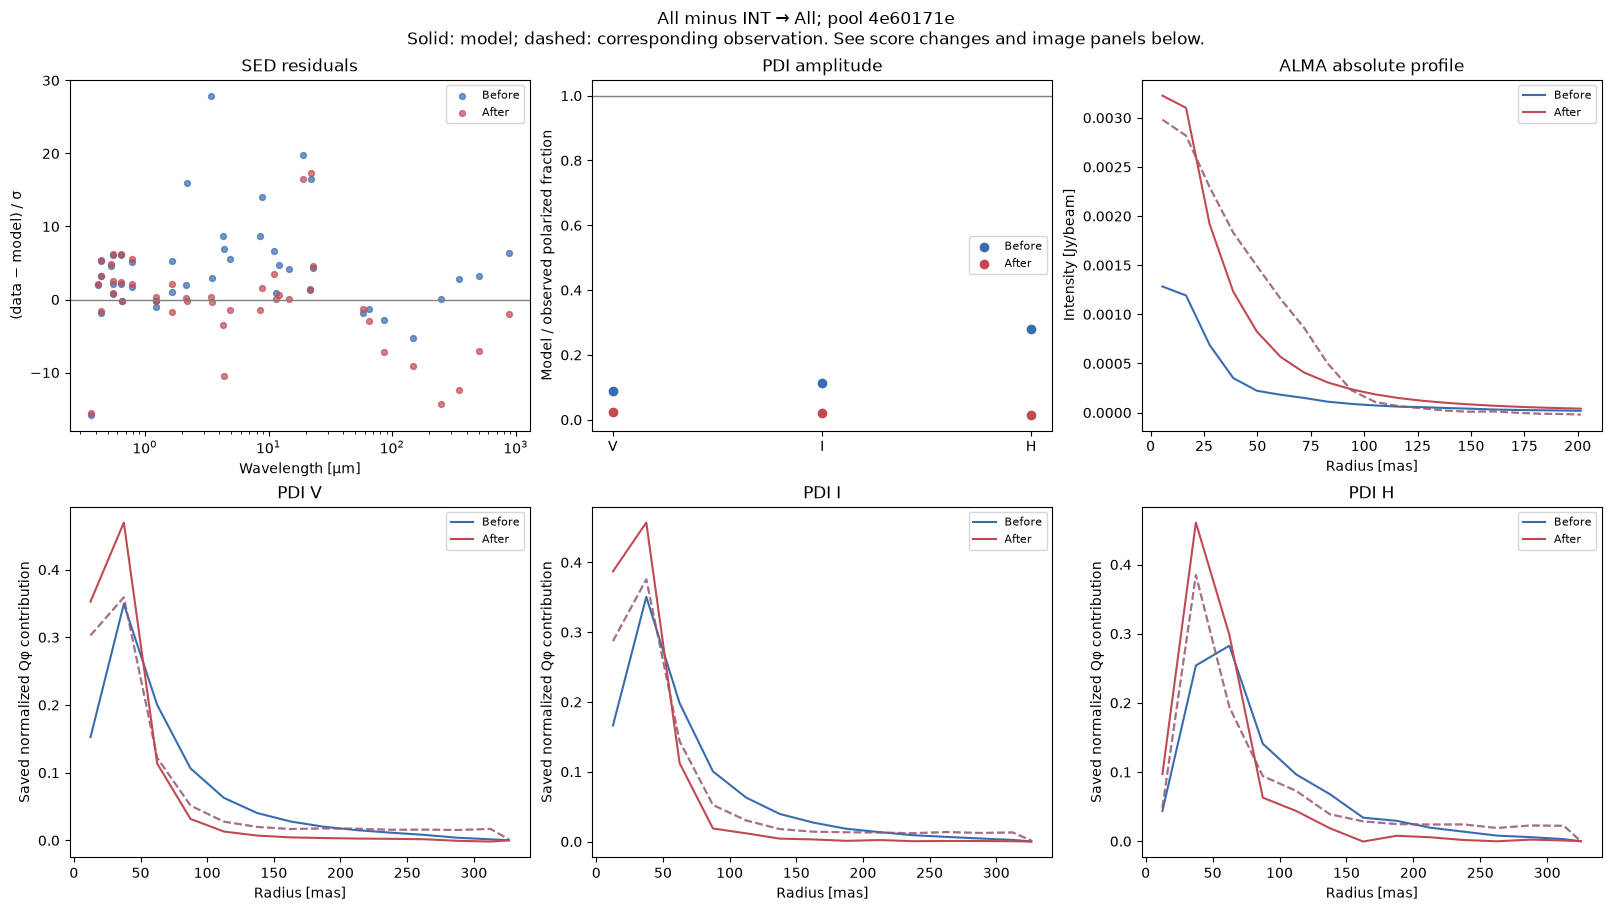

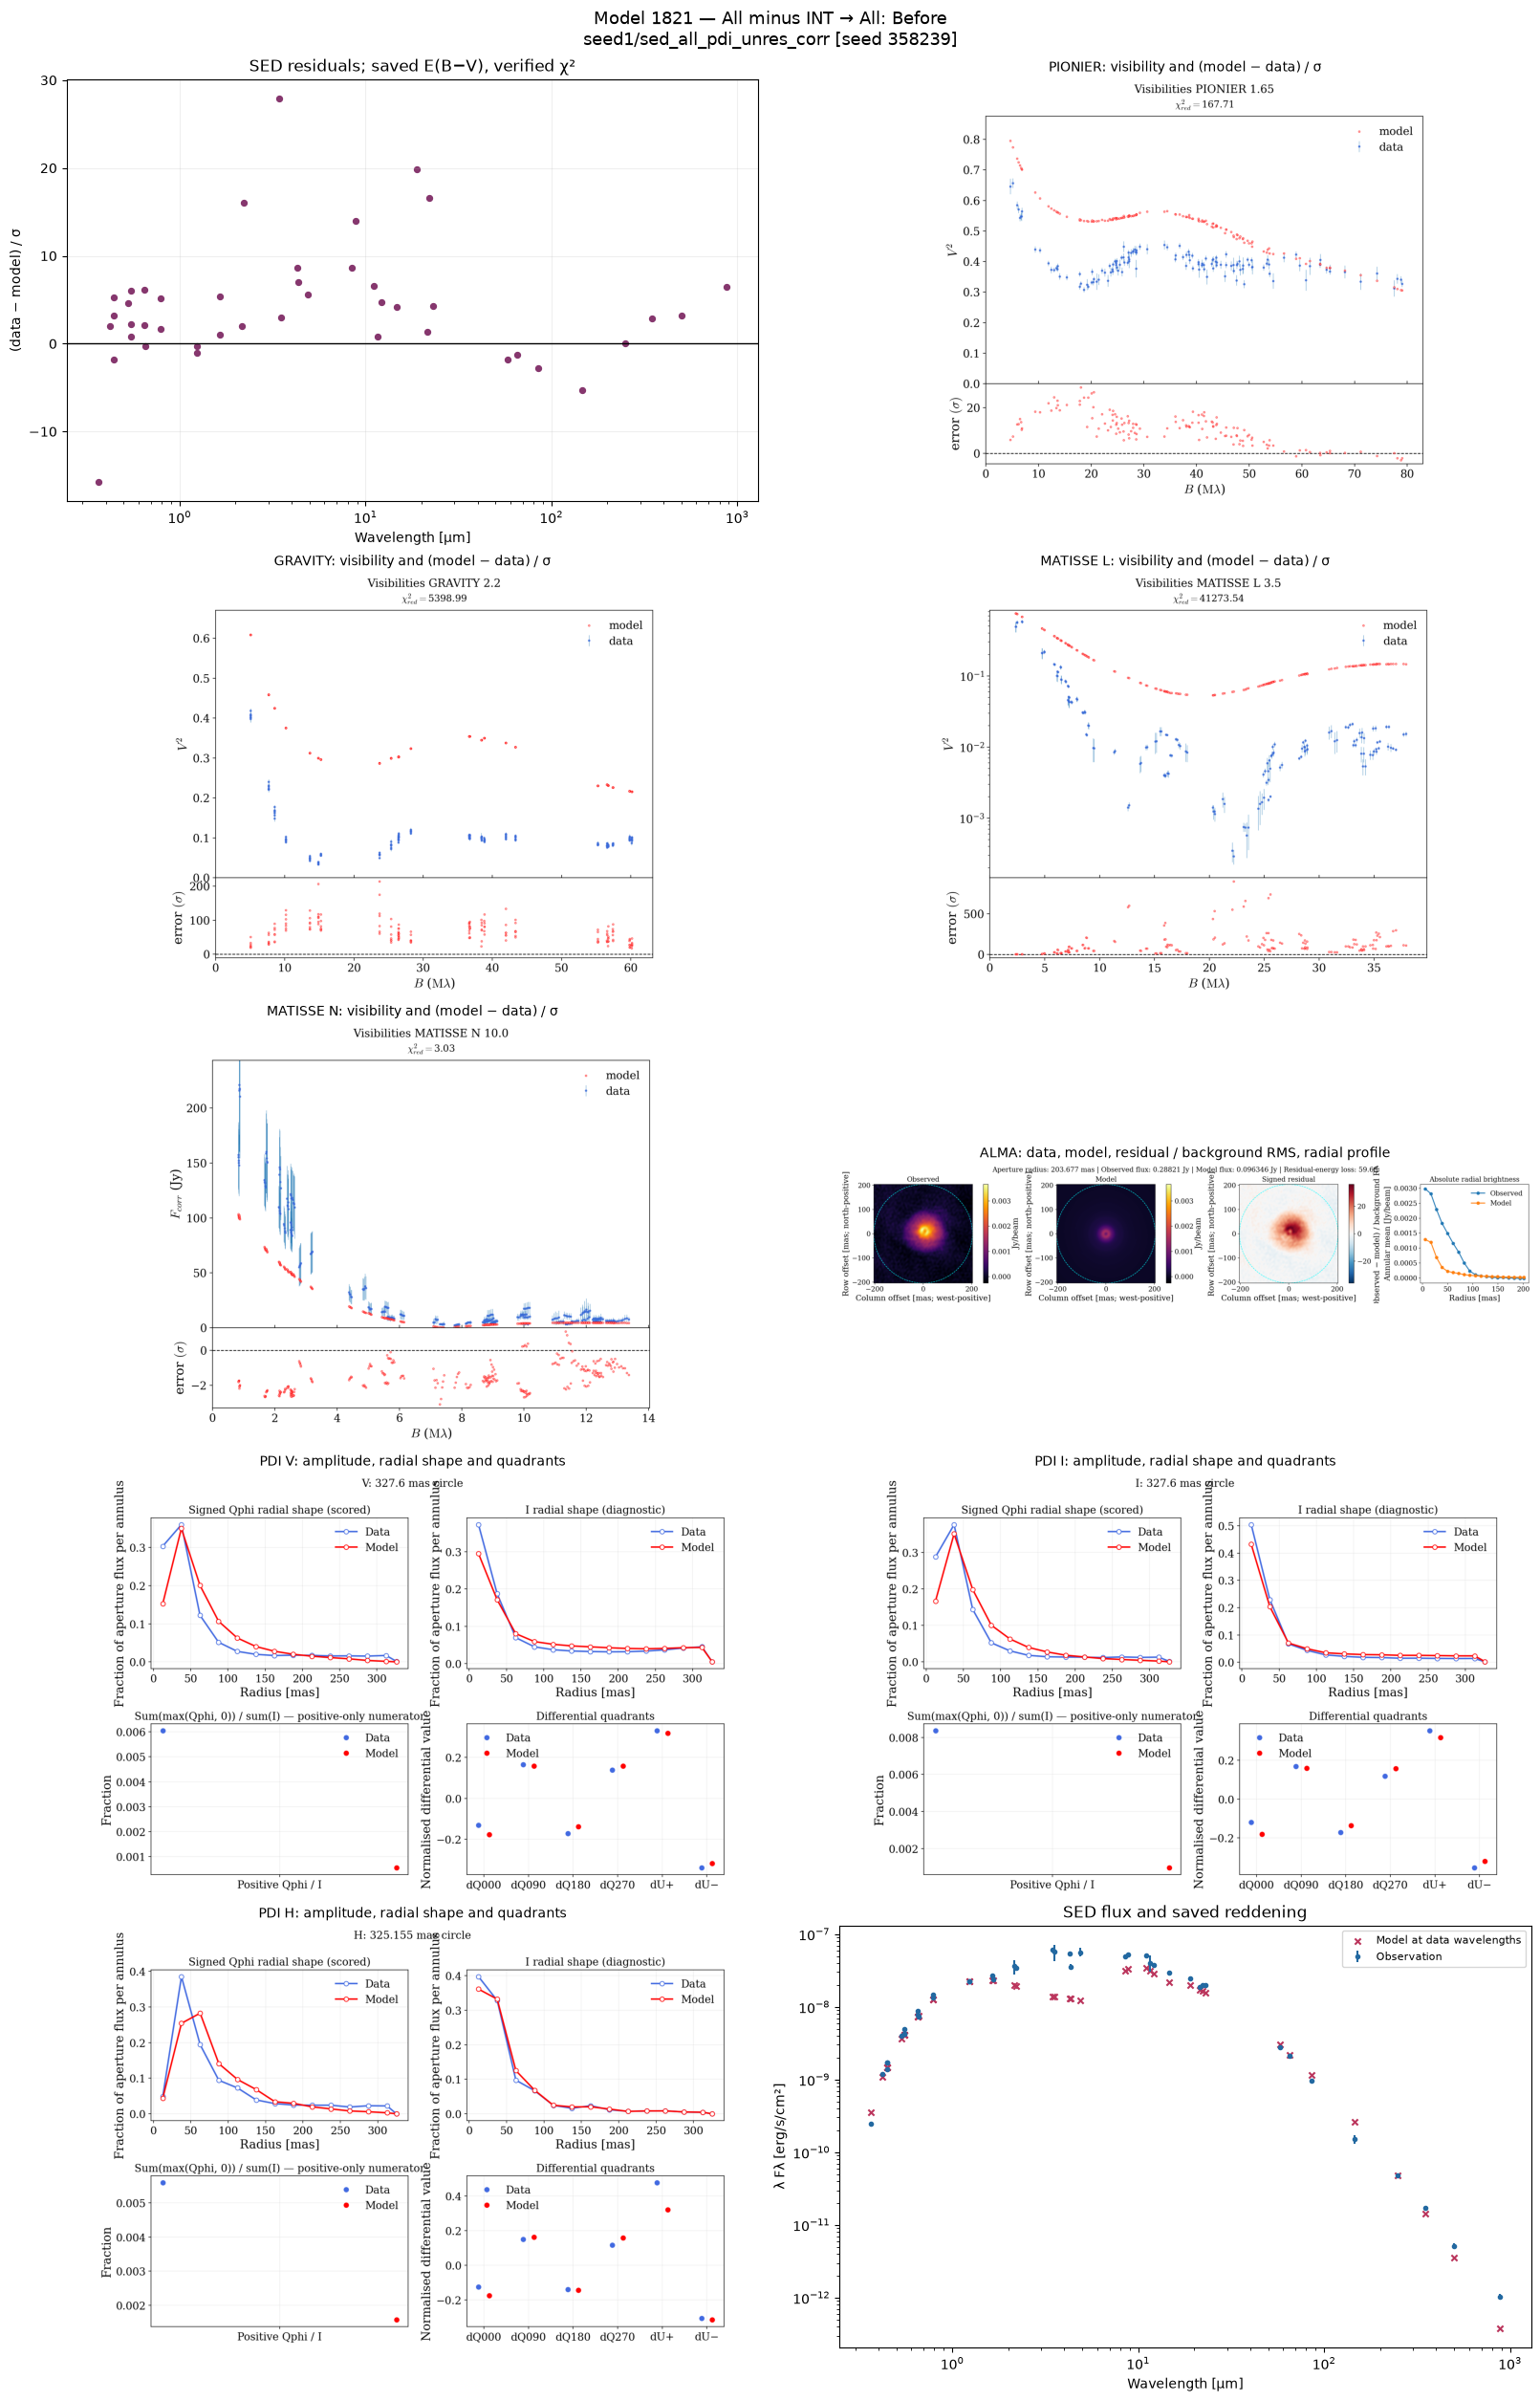

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_59_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_59_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_59_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_59_budget_1.00/figures/pdi_constraints_h.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_59_budget_1.00/figures/pdi_constraints_h_model_quadrants_slides.png

...

Before: seed1/sed_all_pdi_unres_corr [seed 358239]/row_253 | After: seed1/sed_all_pdi_unres_corr [seed 358239]/row_253


,parameter,before,after
0,alpha_viscosity,0.100000,0.100000
1,disk_Rmid,20.880817,20.880817
2,disk_pa,139.000000,139.000000
3,disk_total_dust_mass,0.009671,0.009671
4,inclination,27.000000,27.000000
5,zone_1_Rin,7.404738,7.404738
6,zone_1_flaring_exp,0.966110,0.966110
7,zone_1_scale_height,1.768164,1.768164
8,zone_1_species_1_Vmax,0.660324,0.660324
9,zone_1_species_1_aexp,2.678069,2.678069


,observation,term,before,after,comparable,change
0,SED,score_sed,41.342390,41.342390,True,0.0
1,INT,score_pionier,19.720194,19.720194,True,0.0
2,INT,score_gravity,78.181834,78.181834,True,0.0
3,INT,score_matisse_l,62.459222,62.459222,True,0.0
4,INT,score_matisse_n,2.928977,2.928977,True,0.0
5,PDI,score_pdi_V,417.996272,417.996272,True,0.0
6,PDI,score_pdi_I,524.359088,524.359088,True,0.0
7,PDI,score_pdi_H,702.488005,702.488005,True,0.0
8,ALMA,score_alma,21.306347,21.306347,True,0.0


,evaluation_id,history,band,observed_fraction,model_fraction,model_over_observed,corrected,correction_radius_px,fraction_loss,radial_loss,quadrant_loss,band_loss,ssim_diagnostic,representative
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,0.000185,0.022099,True,3.0,6.693604,14.437227,503.228256,524.359088,0.832597,Before = After
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,0.000144,0.023749,True,3.0,3.484962,12.206710,402.304600,417.996272,0.814381,Before = After
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,0.000088,0.015765,True,3.0,3.035761,17.422114,682.030130,702.488005,0.714139,Before = After


,evaluation_id,history,observed_flux_jy,model_flux_jy,model_to_observed_flux,residual_energy_loss,aperture_radius_mas,representative
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.260712,0.904601,21.306347,203.676503,Before = After


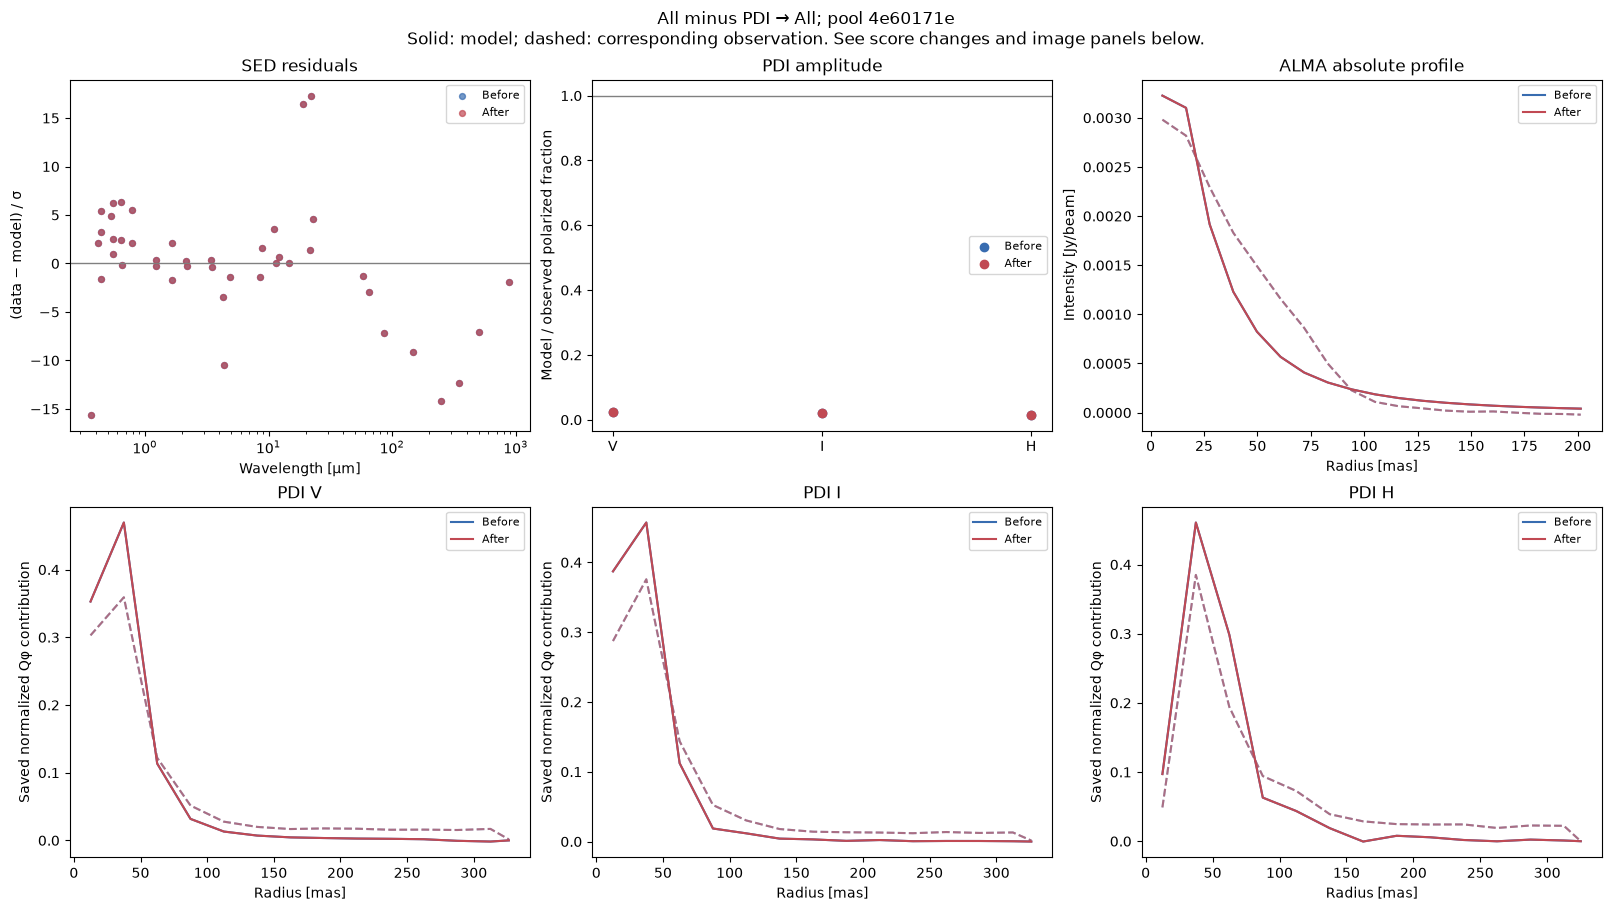

Before = After: Model 1754 — fit page already displayed above.


/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_254_budget_1.00/figures/pdi_constraints_h.png

...

Before: seed1/sed_all_pdi_unres_corr [seed 358239]/row_275 | After: seed1/sed_all_pdi_unres_corr [seed 358239]/row_253


,parameter,before,after
0,alpha_viscosity,0.000010,0.100000
1,disk_Rmid,26.135861,20.880817
2,disk_pa,101.000000,139.000000
3,disk_total_dust_mass,0.049086,0.009671
4,inclination,14.000000,27.000000
5,zone_1_Rin,7.612450,7.404738
6,zone_1_flaring_exp,0.945114,0.966110
7,zone_1_scale_height,2.082912,1.768164
8,zone_1_species_1_Vmax,0.757587,0.660324
9,zone_1_species_1_aexp,2.283991,2.678069


,observation,term,before,after,comparable,change
0,SED,score_sed,198.590777,41.342390,True,-157.248388
1,INT,score_pionier,215.756874,19.720194,True,-196.036680
2,INT,score_gravity,129.648058,78.181834,True,-51.466224
3,INT,score_matisse_l,132.904098,62.459222,True,-70.444876
4,INT,score_matisse_n,68.484085,2.928977,True,-65.555108
5,PDI,score_pdi_V,286.285262,417.996272,True,131.711010
6,PDI,score_pdi_I,324.172684,524.359088,True,200.186404
7,PDI,score_pdi_H,491.016483,702.488005,True,211.471522
8,ALMA,score_alma,29.046151,21.306347,True,-7.739804


,evaluation_id,history,band,observed_fraction,model_fraction,model_over_observed,corrected,correction_radius_px,fraction_loss,radial_loss,quadrant_loss,band_loss,ssim_diagnostic,representative
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,0.000185,0.022099,True,3.0,6.693604,14.437227,503.228256,524.359088,0.832597,After
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,0.000144,0.023749,True,3.0,3.484962,12.206710,402.304600,417.996272,0.814381,After
2,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,0.000088,0.015765,True,3.0,3.035761,17.422114,682.030130,702.488005,0.714139,After
3,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],I,0.008366,0.000095,0.011321,True,3.0,6.841963,9.861602,307.469119,324.172684,0.865111,Before
4,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],V,0.006047,0.000040,0.006598,True,3.0,3.608492,11.037914,271.638856,286.285262,0.860496,Before
5,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],H,0.005598,0.000200,0.035662,True,3.0,2.914256,15.015393,473.086834,491.016483,0.733463,Before


,evaluation_id,history,observed_flux_jy,model_flux_jy,model_to_observed_flux,residual_energy_loss,aperture_radius_mas,representative
0,seed1/sed_all_pdi_unres_corr [seed 358239]/row_253,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.260712,0.904601,21.306347,203.676503,After
1,seed1/sed_all_pdi_unres_corr [seed 358239]/row_275,seed1/sed_all_pdi_unres_corr [seed 358239],0.288207,0.521916,1.810909,29.046151,203.676503,Before


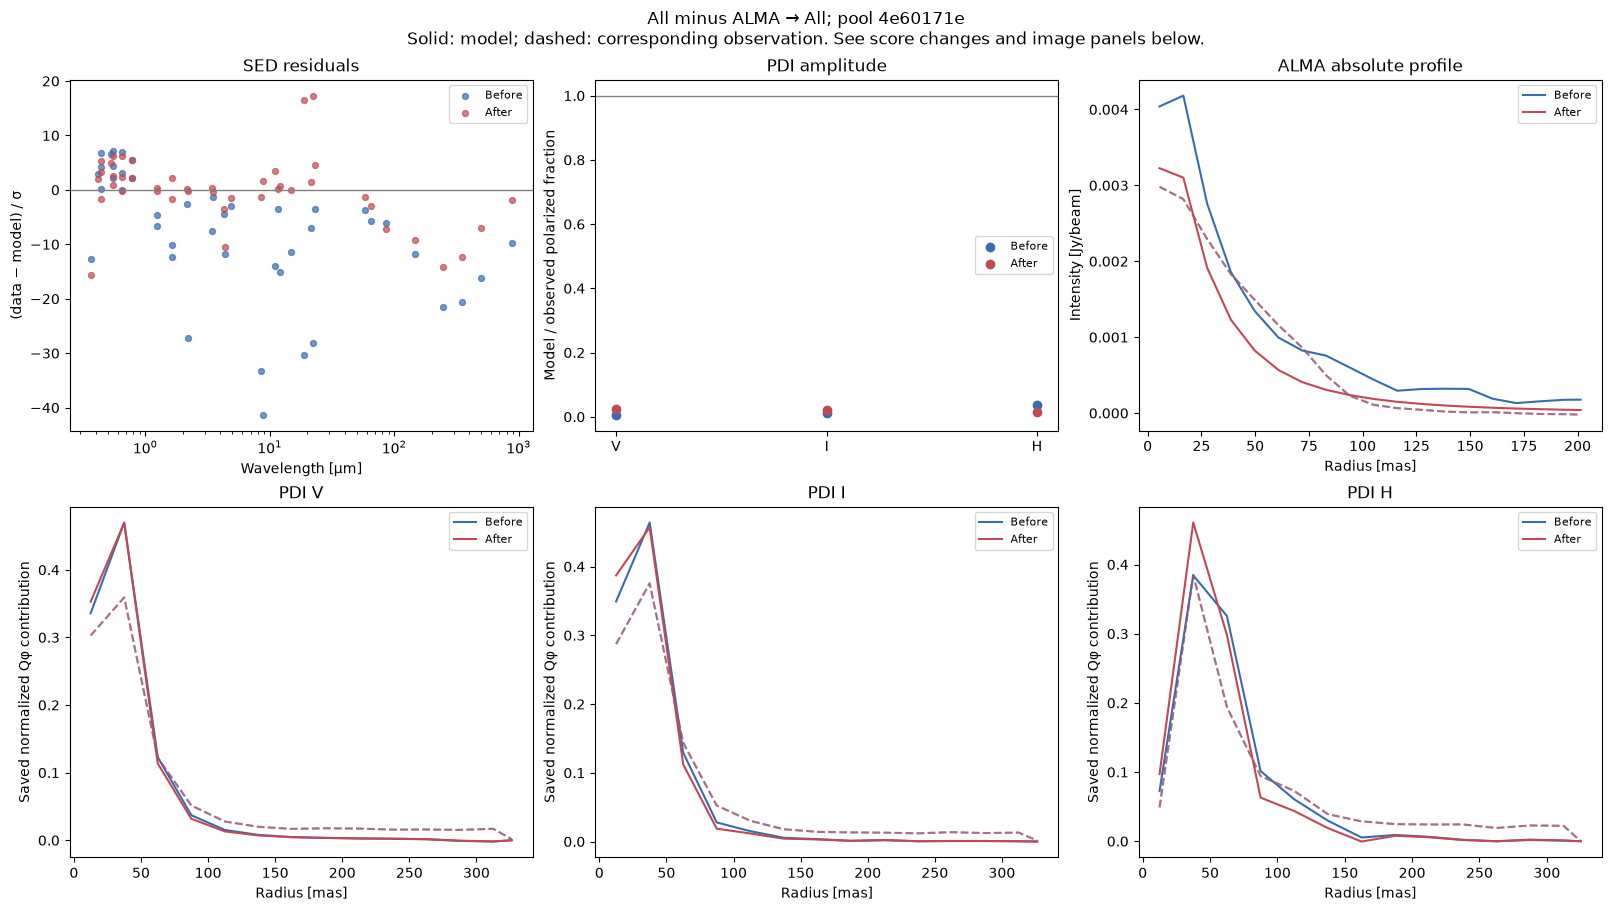

Before: Model 1778 — fit page already displayed above.


/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/alma_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/trials/config_276_budget_1.00/figures/pdi_constraints_h.png

...

Before: seed1/sed_alma [seed 769887]/row_664 | After: seed1/sed_alma [seed 769887]/row_980


,parameter,before,after
0,alpha_viscosity,0.001000,0.001000
1,disk_Rmid,29.771195,29.474164
2,disk_pa,90.000000,90.000000
3,disk_total_dust_mass,0.007516,0.008039
4,inclination,45.000000,37.000000
5,zone_1_Rin,6.716658,6.448390
6,zone_1_flaring_exp,0.704075,0.725190
7,zone_1_scale_height,2.295806,2.194126
8,zone_1_species_1_Vmax,0.740199,0.704351
9,zone_1_species_1_aexp,2.968416,2.931714


,observation,term,before,after,comparable,change
0,SED,score_sed,17.494229,18.434243,True,0.940014
1,INT,score_pionier,NaN,NaN,False,NaN
2,INT,score_gravity,NaN,NaN,False,NaN
3,INT,score_matisse_l,NaN,NaN,False,NaN
4,INT,score_matisse_n,NaN,NaN,False,NaN
5,PDI,score_pdi_V,NaN,NaN,False,NaN
6,PDI,score_pdi_I,NaN,NaN,False,NaN
7,PDI,score_pdi_H,NaN,NaN,False,NaN
8,ALMA,score_alma,20.068588,17.172632,True,-2.895956


*No compatible evidence available for this table.*

,evaluation_id,history,observed_flux_jy,model_flux_jy,model_to_observed_flux,residual_energy_loss,aperture_radius_mas,representative
0,seed1/sed_alma [seed 769887]/row_664,seed1/sed_alma [seed 769887],0.288207,0.266622,0.925106,20.068588,203.676503,Before
1,seed1/sed_alma [seed 769887]/row_980,seed1/sed_alma [seed 769887],0.288207,0.291015,1.009745,17.172632,203.676503,After


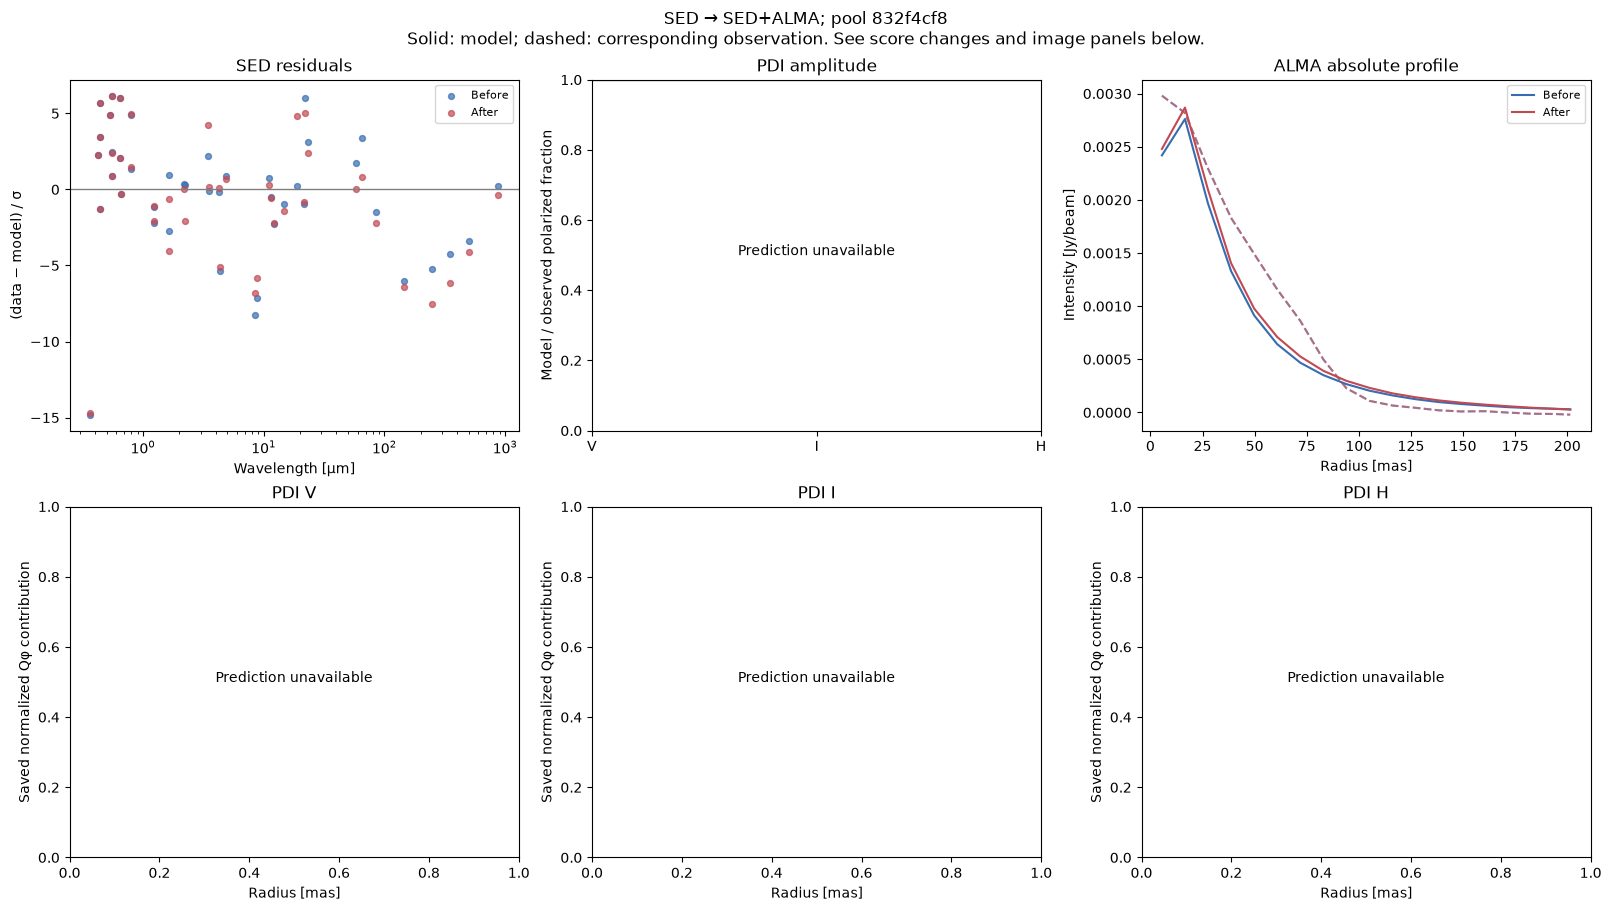

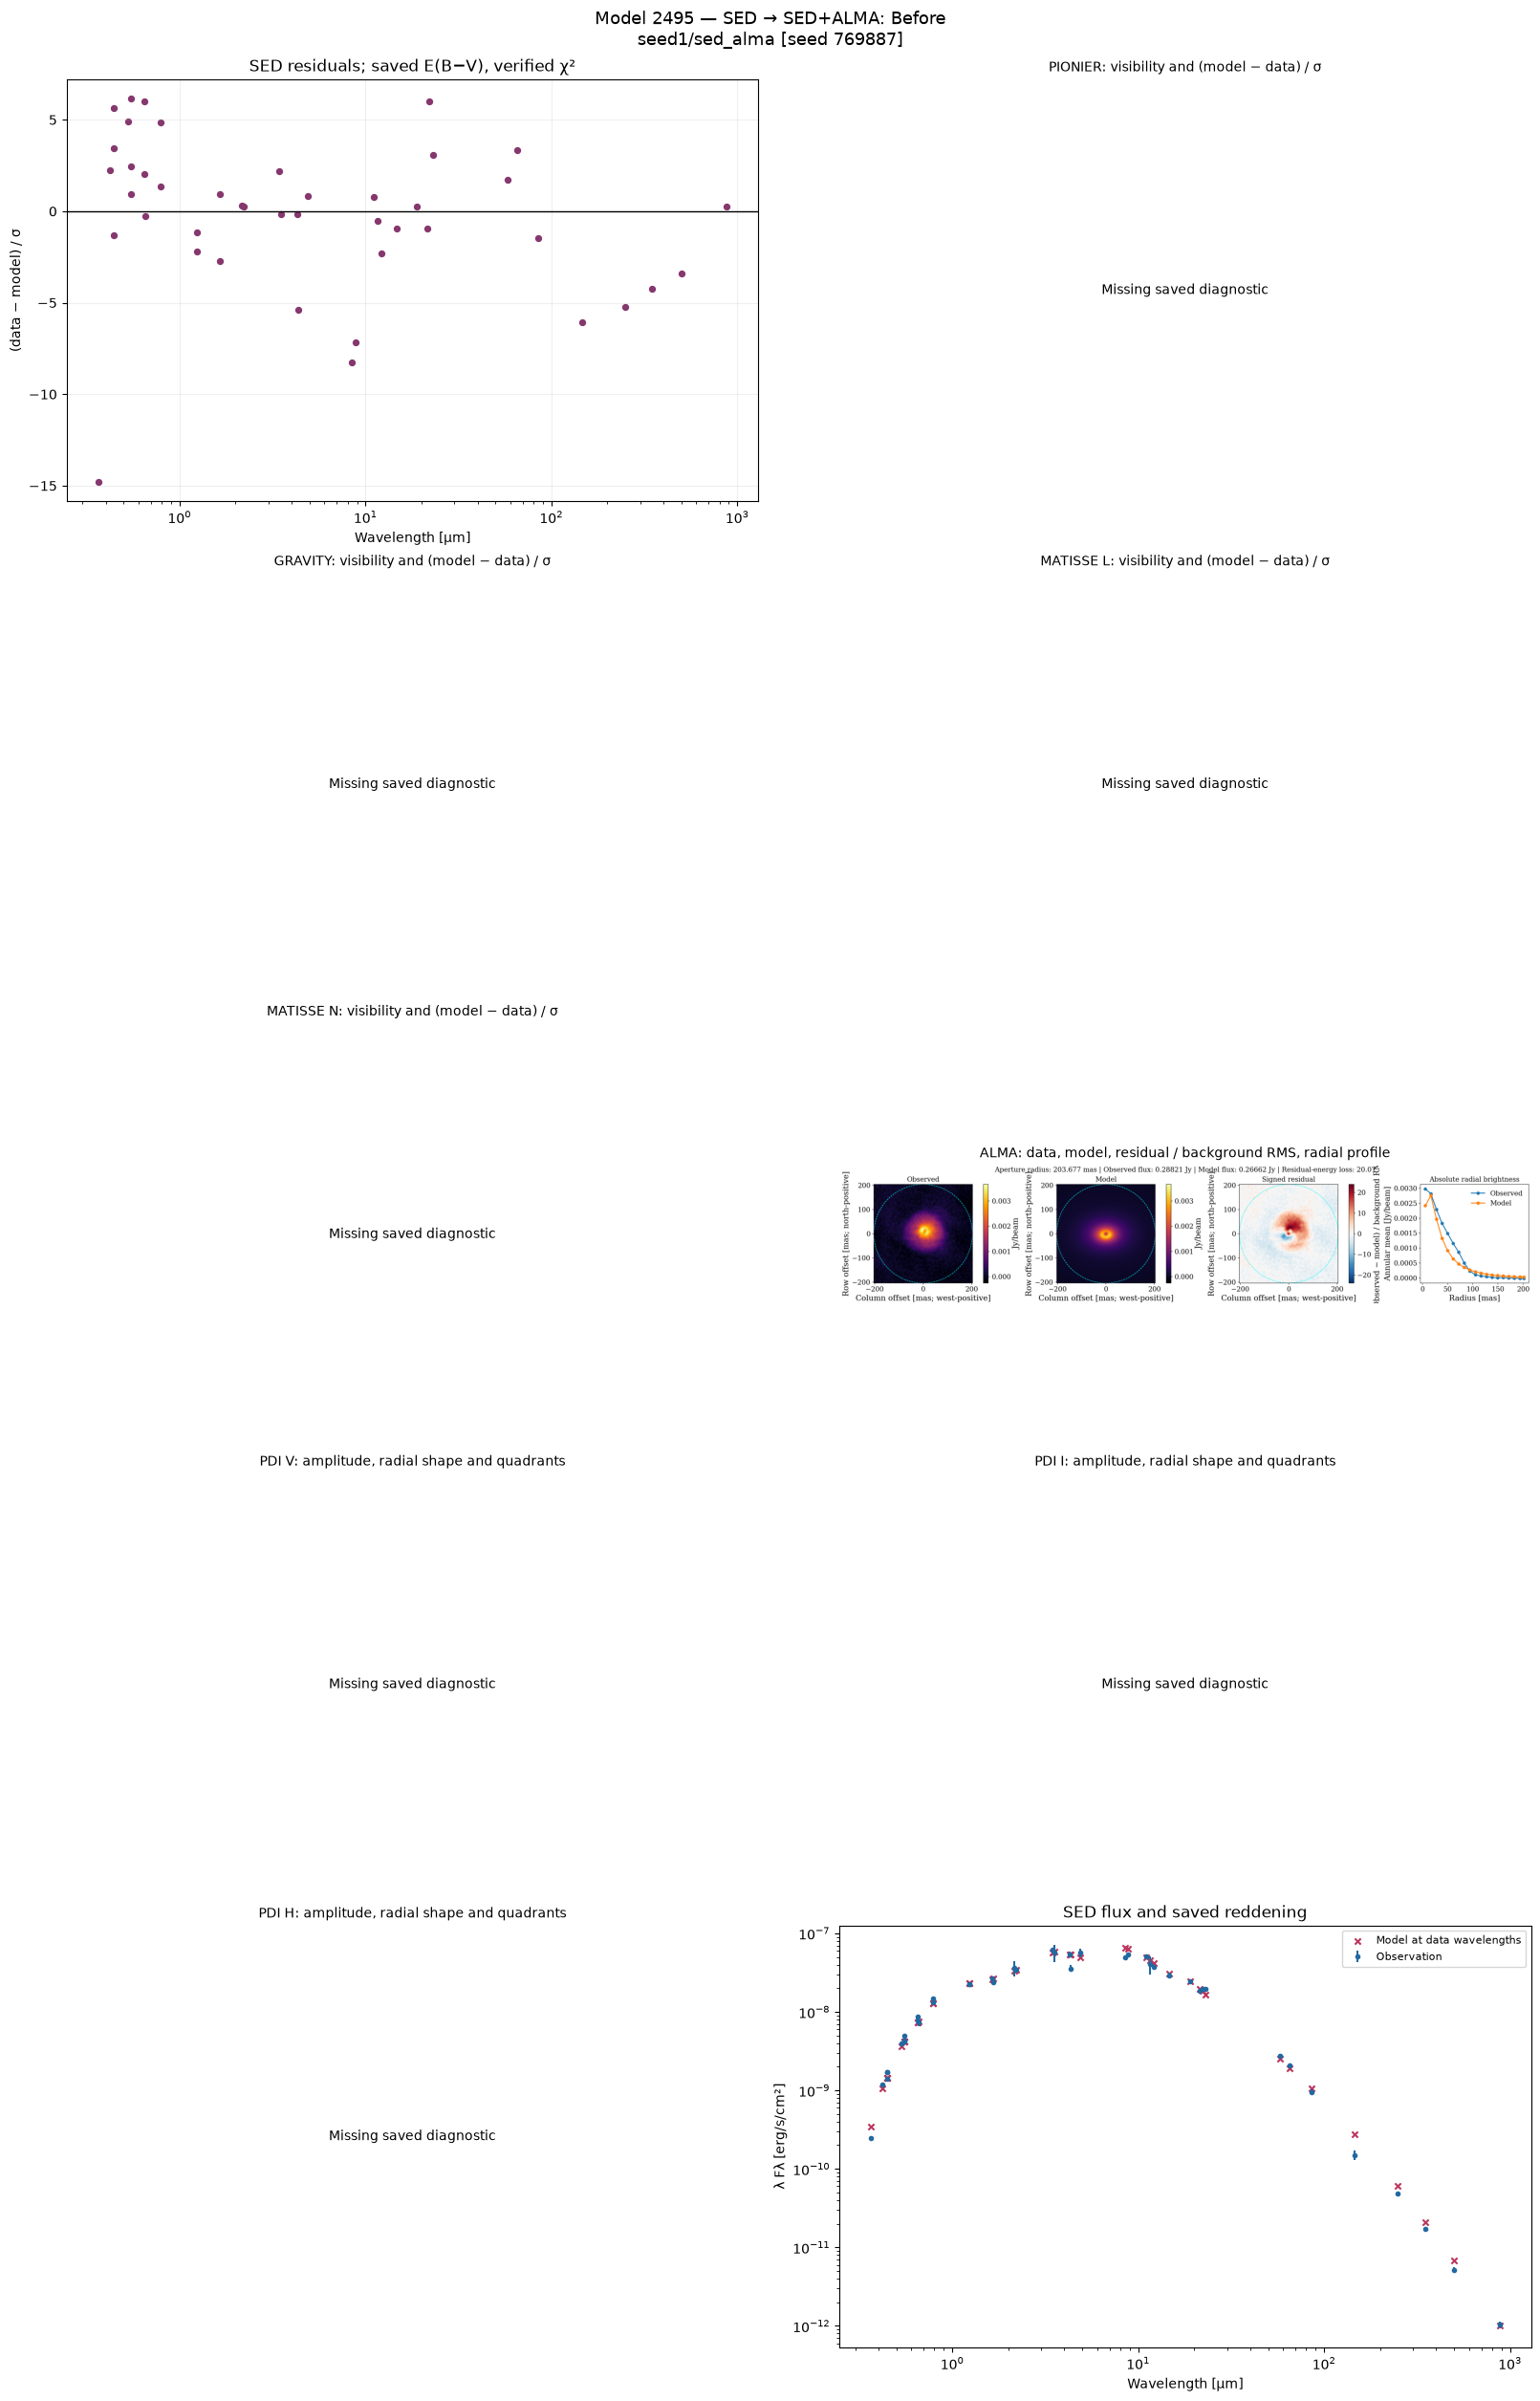

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_665_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_665_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_665_budget_1.00/figures/alma_comparison.png

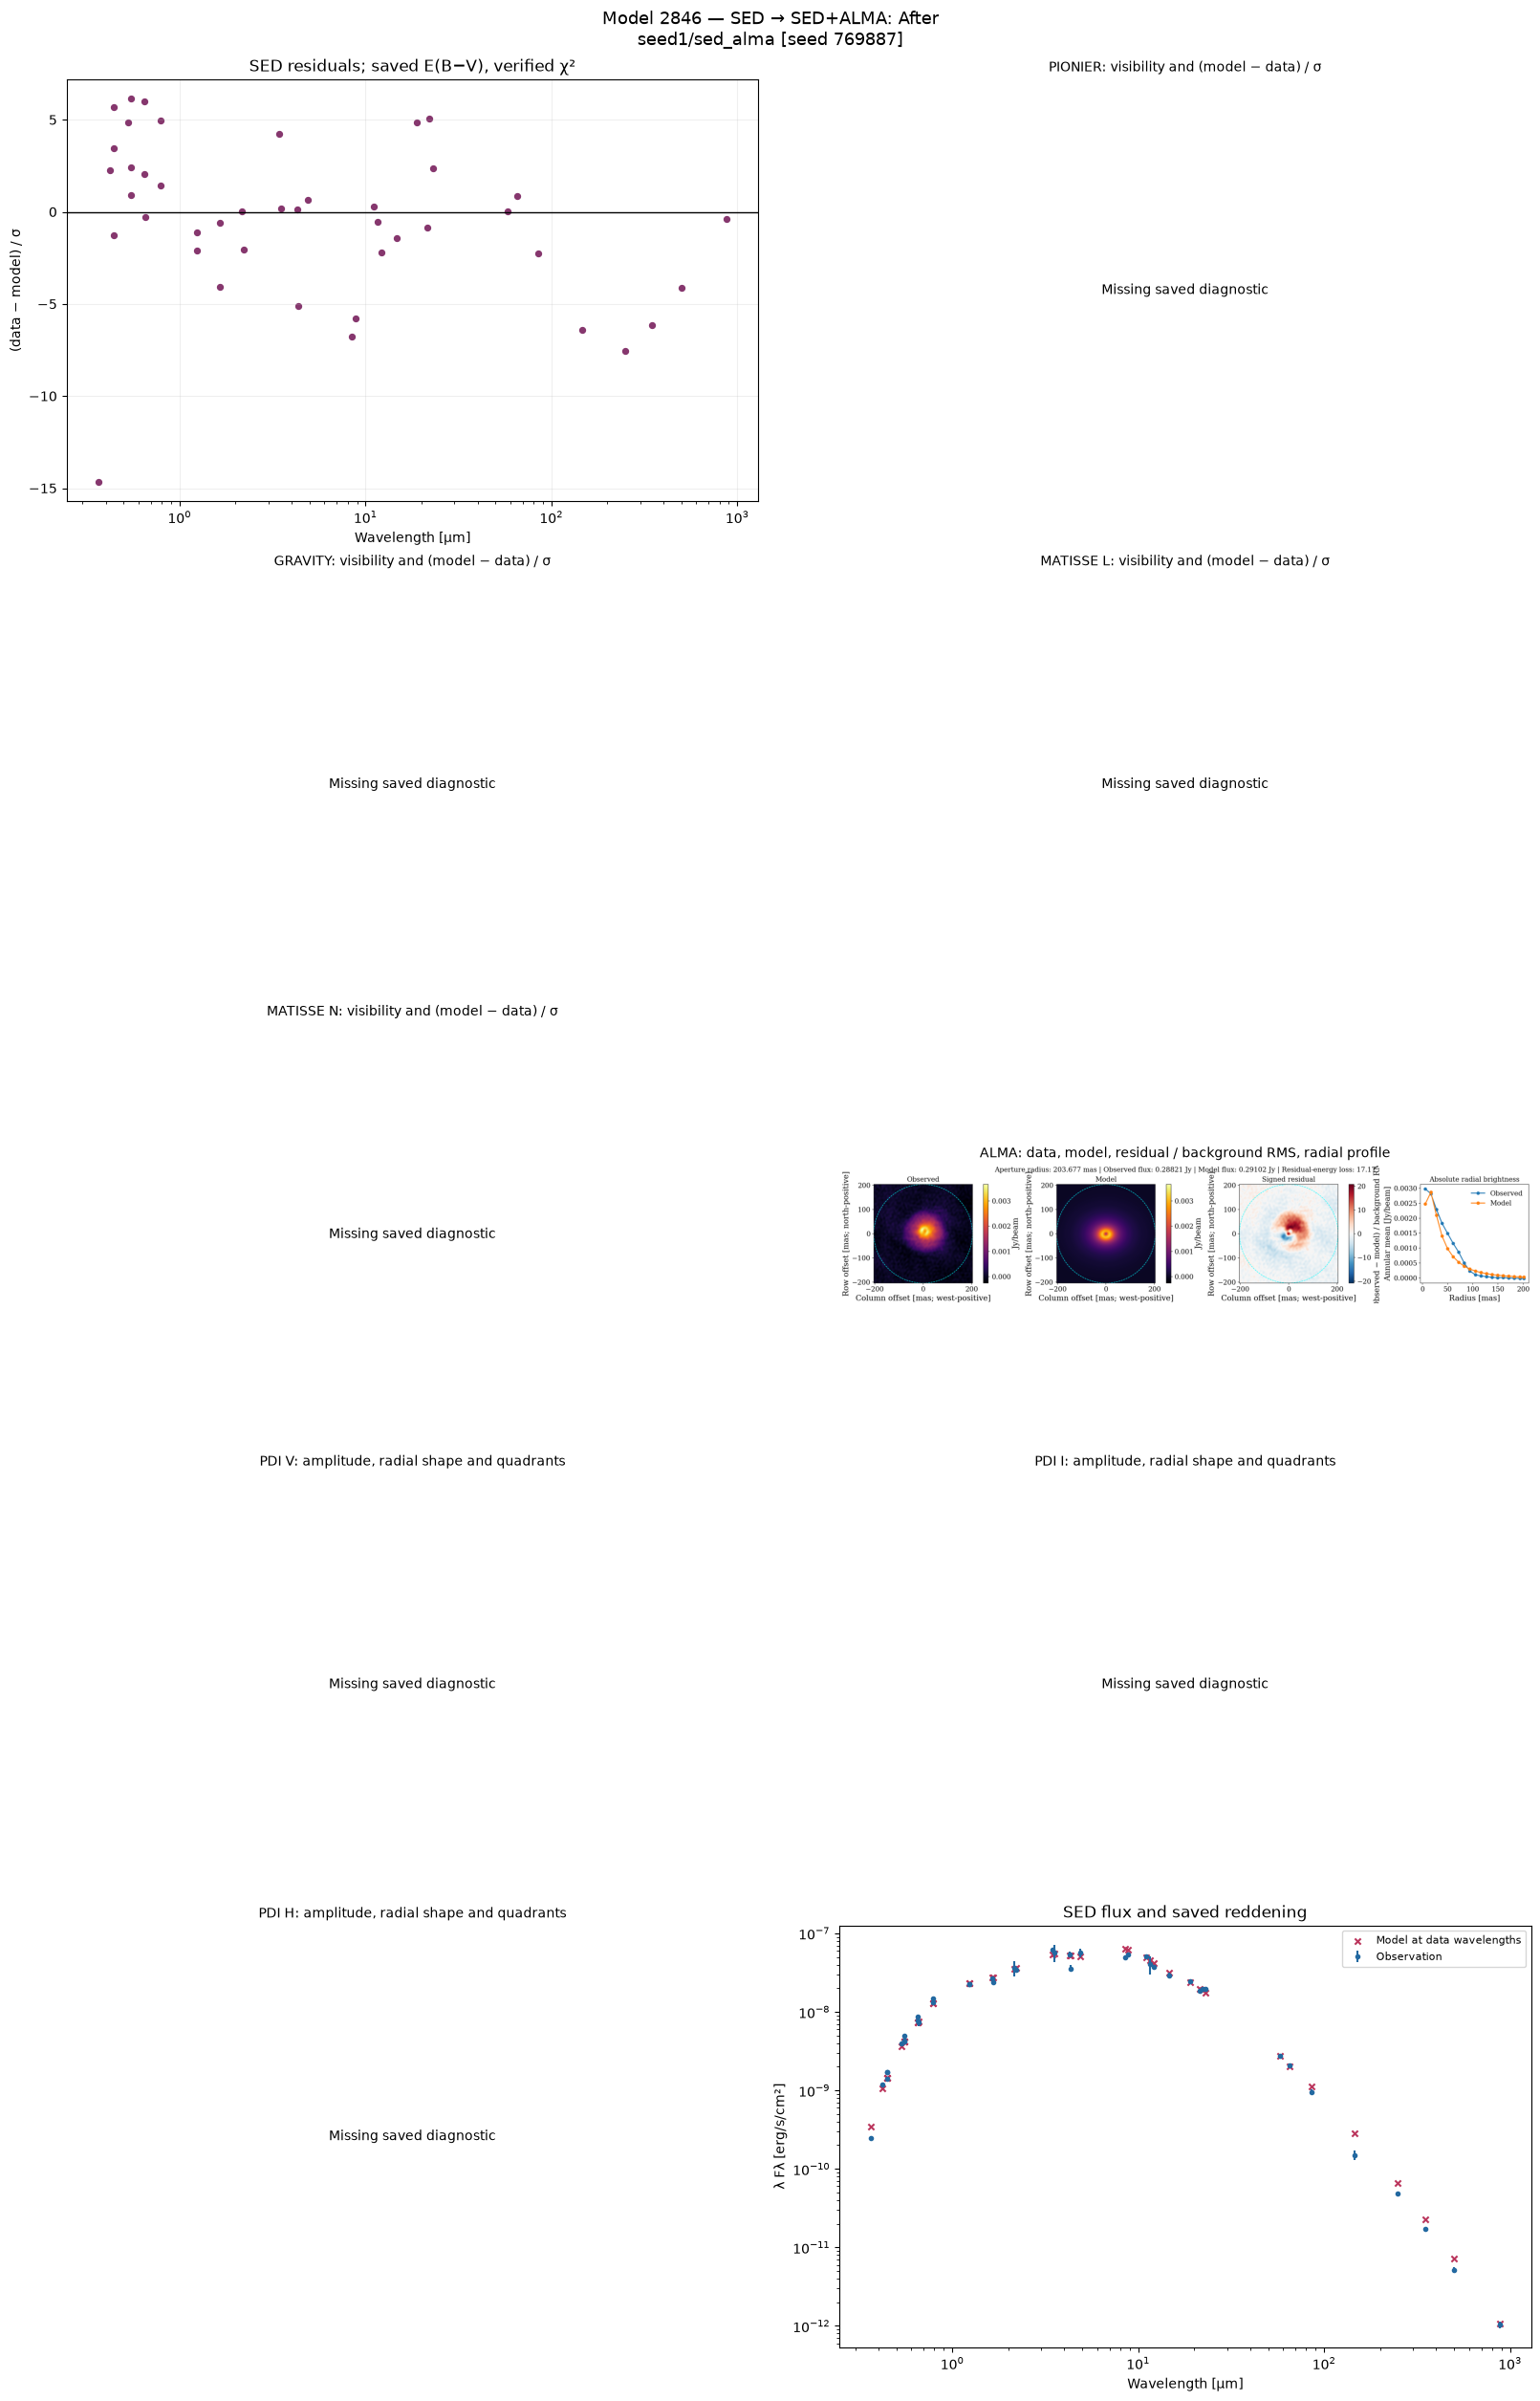

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_981_budget_1.00/SED_Akke_model1_MCFOST.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_981_budget_1.00/SED_secondary_comparison.png

/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/trials/config_981_budget_1.00/figures/alma_comparison.png

In [7]:
show_table(prediction_pairs)
view_pairs = prediction_pairs.loc[
    [(row.before, row.after) in PAIR_VIEWS for row in prediction_pairs.itertuples()]
].copy() if not prediction_pairs.empty else prediction_pairs.copy()
pair_selection = candidates.loc[candidates.evaluation_id.isin(
    set(view_pairs.before_id) | set(view_pairs.after_id))].copy() if not view_pairs.empty else candidates.iloc[:0]
pair_folders, pair_folder_audit = fa.resolve_diagnostics(pair_selection, records)
pair_sed, pair_sed_audit = fa.load_sed_diagnostics(
    pair_selection, records, pair_folders, SED_PHOTOMETRY, REDDENING_LAW,
    SED_RECIPE, SED_RECIPE_BY_HISTORY)
show_table(pair_folder_audit)
show_table(pair_sed_audit)
for pair in view_pairs.itertuples(index=False):
    display(Markdown(f"### {pair.before} → {pair.after} / pool `{pair.score_pool_key[:8]}`"))
    parameters, score_changes, pdi_changes, alma_changes = fa.pair_changes(
        pair, candidates, records, references)
    id_labels = ({pair.before_id: "Before = After"} if pair.before_id == pair.after_id
                 else {pair.before_id: "Before", pair.after_id: "After"})
    if pair.before_id == pair.after_id:
        display(Markdown("**The same saved model minimizes both objectives in this pool.**"))
    print("Before:", pair.before_id, "| After:", pair.after_id)
    show_table(parameters)
    show_table(score_changes)
    show_table(pdi_changes.assign(representative=pdi_changes.evaluation_id.map(id_labels))
               if not pdi_changes.empty else pdi_changes)
    show_table(alma_changes.assign(representative=alma_changes.evaluation_id.map(id_labels))
               if not alma_changes.empty else alma_changes)
    fig = fa.plot_prediction_pair(pair, records, pair_sed)
    display(fig)
    plt.close(fig)
    if SHOW_PAIR_IMAGES:
        # Retain the original spatial residuals and all instruments for both models.
        for model_id in dict.fromkeys([pair.before_id, pair.after_id]):
            row = pair_selection.loc[pair_selection.evaluation_id.eq(model_id)].iloc[0]
            if model_id not in displayed_fit_ids:
                fig = fa.plot_fit_page(row, pair_folders.get(model_id), pair_sed.get(model_id),
                                       f"{pair.before} → {pair.after}: {id_labels[model_id]}")
                display(fig)
                plt.close(fig)
                displayed_fit_ids.add(model_id)
            else:
                print(f"{id_labels[model_id]}: {row.model_id} — fit page already displayed above.")
            for path in fa.diagnostic_paths(pair_folders.get(model_id)):
                display(FileLink(str(path)))

## 4. One compact robustness check, plus cross-group pairs

The grid combines nearby cutoffs (30/40/50%), equal weights and three descriptive score-weight settings, and evaluation versus unique-configuration counting.

For score weighting, `w ∝ 2**(-(J − Jmin)/delta)`, where `delta = half_weight_fraction * abs(Jmin)`. Thus `delta` is the score increase that halves the weight; it is **not an observation uncertainty or calibrated likelihood temperature**. A zero minimum requires an explicit positive absolute delta. When set, `ABSOLUTE_HALF_DELTA` replaces the relative delta for every exponential-weight setting (so those settings coincide). Equal weights omit this convention entirely. Weighting applies only inside each retained subset and does not correct SMAC's adaptive sampling density.

For unique-configuration counting, repeated compatible evaluations are replaced by their **mean saved objective score per configuration before selecting the fraction**; each retained configuration then has one base vote. This is an analysis sensitivity check, not a change to any recorded model score. Reported ESS is weight concentration, not MCMC effective sample size.

The compact result reports how much the median moves across the grid (in allowed linear/log span), or whether the dominant category changes. This assesses the selected sample's sensitivity, not stability across new optimiser seeds, physical setups, or unvisited models. The addition table separately checks whether narrowing persists across cutoffs.

,parameter,support,robustness,strongest_narrowing
0,alpha_viscosity,105 unique / 105 evaluations,Dominant categories: 0.1,not defined for categories
1,disk_Rmid,105 unique / 105 evaluations,Median span: 17.5% of allowed coordinate span; 10–90% width: 17.5%–82.2% of span,All minus INT → All [4e60171e]: ×0.98; cutoff sensitive | All minus PDI → All [4e60171e]: ×1; cutoff sensitive
2,disk_pa,105 unique / 105 evaluations,Median span: 4.4% of allowed coordinate span; 10–90% width: 42.2%–77.8% of span,SED → SED+INT [8d640dae]: ×0.86; all cutoffs | All minus PDI → All [4e60171e]: ×0.95; all cutoffs
3,disk_total_dust_mass,105 unique / 105 evaluations,Median span: 16.9% of allowed coordinate span; 10–90% width: 23.5%–78.5% of span,SED → SED+INT [8d640dae]: ×0.88; all cutoffs | All minus SED → All [4e60171e]: ×0.99; cutoff sensitive
4,inclination,105 unique / 105 evaluations,Median span: 26.0% of allowed coordinate span; 10–90% width: 26.0%–74.0% of span,SED → SED+PDI [58c68d21]: ×0.83; all cutoffs | SED → SED+INT [8d640dae]: ×0.89; all cutoffs
5,zone_1_Rin,105 unique / 105 evaluations,Median span: 10.8% of allowed coordinate span; 10–90% width: 5.7%–82.4% of span,SED → SED+INT [8d640dae]: ×0.83; all cutoffs | All minus INT → All [4e60171e]: ×0.95; all cutoffs
6,zone_1_flaring_exp,105 unique / 105 evaluations,Median span: 27.9% of allowed coordinate span; 10–90% width: 5.0%–73.2% of span,All minus PDI → All [4e60171e]: ×0.9; all cutoffs | All minus INT → All [4e60171e]: ×0.9; all cutoffs
7,zone_1_scale_height,105 unique / 105 evaluations,Median span: 4.4% of allowed coordinate span; 10–90% width: 12.6%–71.8% of span,SED → SED+INT [8d640dae]: ×0.93; all cutoffs | All minus INT → All [4e60171e]: ×0.95; all cutoffs
8,zone_1_species_1_Vmax,105 unique / 105 evaluations,Median span: 30.5% of allowed coordinate span; 10–90% width: 32.4%–84.0% of span,SED → SED+PDI [58c68d21]: ×0.99; cutoff sensitive
9,zone_1_species_1_aexp,105 unique / 105 evaluations,Median span: 24.3% of allowed coordinate span; 10–90% width: 15.8%–77.0% of span,SED → SED+ALMA [832f4cf8]: ×0.96; cutoff sensitive | All minus INT → All [4e60171e]: ×0.97; cutoff sensitive


All requested weighting settings evaluated successfully.


,counting,fraction,half_fraction,selected,min_valid,min_unique,min_ESS
0,configurations,0.3,0.1,79,79,79,3.174031
1,configurations,0.3,0.25,79,79,79,5.364703
2,configurations,0.3,0.5,79,79,79,15.726656
3,configurations,0.3,equal,79,79,79,79.000000
4,configurations,0.4,0.1,105,105,105,3.174031
5,configurations,0.4,0.25,105,105,105,5.364717
6,configurations,0.4,0.5,105,105,105,15.760470
7,configurations,0.4,equal,105,105,105,105.000000
8,configurations,0.5,0.1,131,131,131,3.174031
9,configurations,0.5,0.25,131,131,131,5.364717


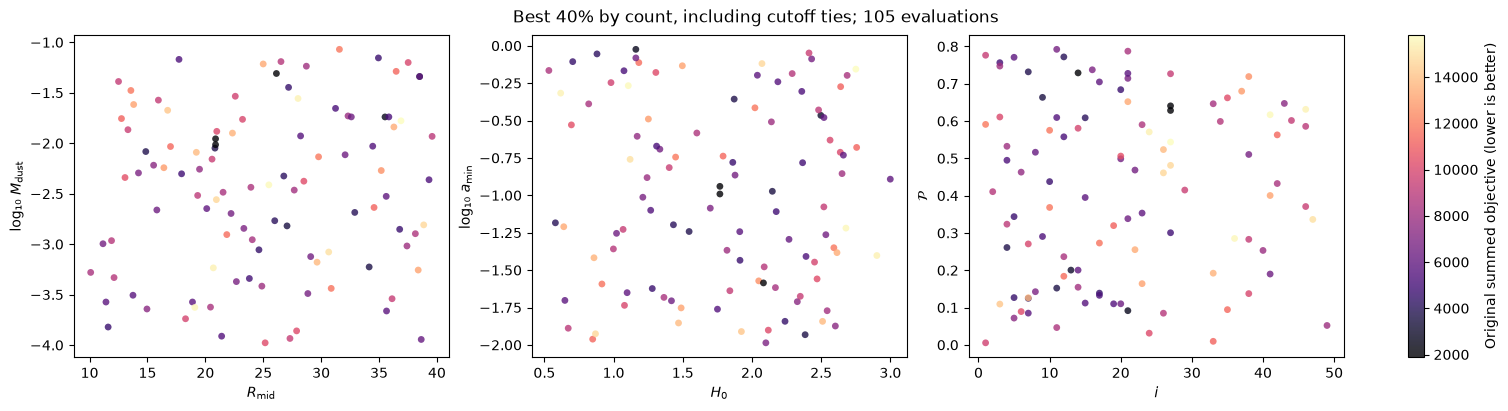

In [8]:
if not evidence.empty:
    show_table(evidence[["parameter", "support", "robustness", "strongest_narrowing"]])
    failures = robustness.loc[robustness.status.ne("ok")]
    if not failures.empty:
        show_table(failures[["parameter", "counting", "fraction", "half_fraction", "status"]])
    else:
        print("All requested weighting settings evaluated successfully.")
    valid_checks = robustness.loc[robustness.status.eq("ok")]
    show_table(valid_checks.groupby(["counting", "fraction", "half_fraction"])
               .agg(selected=("n_selected", "first"), min_valid=("n_valid", "min"),
                    min_unique=("n_unique", "min"), min_ESS=("ess", "min"))
               .reset_index())
    fig, skipped_pairs = fa.plot_cross_pairs(focus, objectives["All"], references,
                                             CROSS_PAIRS, KEEP_FRACTION)
    if fig is not None:
        display(fig)
        plt.close(fig)
    if skipped_pairs:
        print("Pairs absent from this setup:", skipped_pairs)

The cross-group panels retain only the selected best 40% (plus cutoff ties). Color represents the **original joint objective score**, with lower scores better. Axes follow the saved parameter types; numeric categories remain categories, and log coordinates are labeled. These panels expose relations hidden when geometry/orientation and dust/composition are plotted separately.

## Coverage and optional snapshot export

Inspect the coverage when a table is empty or a result changes after new models arrive. Different physical pools are never merged. All scoring partitions are retained for the single-objective minima and observation-addition tables; the compact joint range/robustness view uses the explicitly printed joint partition.

Historical observation identity is not fully recorded. The original run scripts, saved templates and ConfigSpace remain the authority on setup-specific assumptions. The export includes history hashes, selected pool keys, settings, all detailed tables and the SED reconstruction audit. It contains no future-run prescriptions or final decisions.

In [9]:
show_table(physical_coverage)
show_table(coverage)
show_table(addition_coverage)
show_table(inventory[[column for column in ["history", "history_path", "history_sha256",
    "configspace_hash", "template_hash", "recorded_trials", "requested_trials"] if column in inventory]])

if SAVE_TABLES:
    export_dir = EXPORT_ROOT / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    export_dir.mkdir(parents=True, exist_ok=False)
    tables = dict(compact_scorecard=compact_scorecard, scorecard=scorecard, representative_roles=roles, parameter_glossary=glossary,
                  parameter_evidence=evidence, addition_effects=effects, prediction_pairs=prediction_pairs,
                  robustness=robustness, physical_coverage=physical_coverage, objective_coverage=coverage,
                  addition_coverage=addition_coverage, inventory=inventory, family_members=family_members,
                  folder_audit=folder_audit, sed_audit=sed_audit, pair_folder_audit=pair_folder_audit,
                  pair_sed_audit=pair_sed_audit, pdi_amplitudes=pdi_amplitudes, alma_amplitudes=alma_amplitudes)
    for name, table in tables.items():
        table.to_csv(export_dir / f"{name}.csv", index=False)
    for number, (model_id, points) in enumerate({**sed_tables, **pair_sed}.items(), 1):
        points.assign(evaluation_id=model_id).to_csv(export_dir / f"sed_points_{number:02d}.csv", index=False)
    manifest = dict(snapshot_time=snapshot_time, run_folders={k: str(v) for k,v in RUN_FOLDERS.items()},
        physical_pool_key=chosen_physical,
        joint_score_pool_key=None if focus.empty else focus.iloc[0].score_pool_key,
        keep_fraction=KEEP_FRACTION, check_fractions=CHECK_FRACTIONS,
        half_weight_fractions=HALF_WEIGHT_FRACTIONS, absolute_half_delta=ABSOLUTE_HALF_DELTA,
        min_unique=MIN_UNIQUE, family_allowance=FAMILY_ALLOWANCE, family_distance=FAMILY_DISTANCE,
        max_alternatives=MAX_ALTERNATIVES, max_family_models=MAX_FAMILY_MODELS,
        sed_photometry=str(SED_PHOTOMETRY), reddening_law=str(REDDENING_LAW),
        sed_recipe=SED_RECIPE, sed_recipe_by_history=SED_RECIPE_BY_HISTORY,
        pair_views=PAIR_VIEWS, cross_pairs=CROSS_PAIRS,
        helper_sha256=file_hash(REPO / "scripts/post-processing/fit_assessment_utils.py"),
        interpretation="Descriptive saved-model snapshot; no calibrated posterior or final model decision.")
    (export_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))
    print("Exported snapshot tables to", export_dir)

,physical_pool,physical_pool_key,evaluations,configurations,histories
0,Physical pool 01,2ce15581a2e1cf1663fdb220005723a557b74f77bf5da149614a96925285d59c,6281,4119,9


,objective,score_pool_key,evaluations,configurations,histories
0,SED,4016ff656864ab1d6fab37728bd838ef6937c1025b1644f099688e71cf688458,5735,3932,8
1,SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4efd6da73d414080819,2071,1375,4
2,SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b33ccf7dea9a86973be9,2537,1840,4
3,SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816d94c0c838bd7f89c71,2438,1740,4
4,SED+INT+PDI,66b7dacb87e5f439117f5b815c0a6a59bcee9636bcd9428bef0b7dc341617765,796,565,2
5,SED+INT+ALMA,533a9a472659940a1555ef852693221eabaf9c88af9778360d1322ce94831a60,571,340,2
6,SED+PDI+ALMA,d5c3700676ef7c0526c1edd1ee767d19711b2207099ad963ac50ffbc6fc76a50,1161,930,2
7,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262,262,1
8,INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4efd6da73d414080819,2617,1562,5
9,PDI,322a76029944bc790547fe9bd3347a140fbc665a15e2f8a9416b6df0e962d572,425,425,1


,before,after,score_pool_key,n_pool
0,All minus SED,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262
1,All minus INT,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262
2,All minus PDI,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262
3,All minus ALMA,All,4e60171e35965935ca56d63f9b7813b84aec394147db95e188a1f7ef554a6a07,262
4,SED,SED+INT,8d640dae29f39fd3be7ea08ca60e14a87ec468888077c4efd6da73d414080819,2071
5,SED,SED+PDI,58c68d21c5d81e5e70598830116922aa63327855d638b33ccf7dea9a86973be9,2537
6,SED,SED+ALMA,832f4cf890fa1d5a48bc79cc982580945792e6e85a7816d94c0c838bd7f89c71,2438


,history,history_path,history_sha256,configspace_hash,template_hash,recorded_trials,requested_trials
0,seed1/int_pdi_alma [seed 878561],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/int_pdi_alma/optimization/878561/runhistory.json,84c3ff8de83a4d24e3baa66d1f90b60c4f85a910b888ba3d5194ca3399bffd16,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,581,1000
1,seed1/sed [seed 193544],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed/optimization/193544/runhistory.json,16312823468348316aee973101f673359af752c0f9c3ee7adf908caf773c270b,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,1000,1000
2,seed1/sed_all_pdi_unres_corr [seed 358239],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_all_pdi_unres_corr/optimization/358239/runhistor...,dc41a9c3ff8242e6cb7cb77da32611a7b724238fc567701f8c79905a4a398131,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,285,1000
3,seed1/sed_alma [seed 769887],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_alma/optimization/769887/runhistory.json,18abfe295af107fd3734fd745f207a382d30edb3c6dd01689205041d462fe64a,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,1000,1000
4,seed1/sed_int_alma [seed 987212],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_alma/optimization/987212/runhistory.json,88d40ccf95ff0c08e1b45c27d9f271637750875060ed172f765e24cc9ff04683,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,332,1000
5,seed1/sed_int_pdi [seed 724769],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_int_pdi/optimization/724769/runhistory.json,73412da66bbced5970c8c2a0cde4a5126b78992d8acde707f8b2bd17ab72928b,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,567,1000
6,seed1/sed_interf [seed 128278],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_interf/optimization/128278/runhistory.json,539b863fdb22bc8e31a496592dca3ede1230342170d05e690e26d4bce952d9c8,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,1000,1000
7,seed1/sed_pdi_alma [seed 171866],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_alma/optimization/171866/runhistory.json,ea33108d236779699cfe460d0fdc222b4fd98b5be1a0cbc164dfd18030f1407b,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,930,1000
8,seed1/sed_pdi_unres_corr [seed 823308],/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/sed_pdi_unres_corr/optimization/823308/runhistory.json,67235173c20fa82b44259383bc686a815373ab8bd3b76224faa5c8ad192930c1,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467dd7fbbe182fd2aa4e3,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5fb71b3980d429cd9c8,874,1000
